In [1]:
%config InlineBackend.figure_formats = ["retina"]

# Istogramma

Una guida completa a `histogram`, la funzione di MesPy che trasforma una serie di misure in un istogramma pronto per una relazione di laboratorio. La pagina parte dall'idea di distribuzione di frequenza e mette la funzione alla prova su undici esempi eseguiti davvero: ogni grafico che vedi è il risultato reale del codice che lo precede.

Se cerchi solo l'elenco dei parametri, salta a [Riferimento API](../moduli/plot_utils/histogram.md). Se è la prima volta che costruisci un istogramma, leggi la pagina dall'alto: ogni sezione usa i concetti della precedente.

(hist-basics)=
## Le basi

(hist-what)=
### Dalle misure alla distribuzione

Quando ripeti più volte la stessa misura, ad esempio il periodo di un pendolo con una fotocellula, non ottieni sempre lo stesso numero. Ogni misura è un'**osservazione**: un singolo valore $x_j$, con $j = 1, \dots, N$. Una lista di cinquanta valori, però, è difficile da leggere a colpo d'occhio: non dice subito dove si concentrano le misure, quanto sono disperse o se ce n'è qualcuna anomala.

Un istogramma risponde a queste domande. Si divide l'asse dei valori in intervalli consecutivi, chiamati **bin**, e si conta quante osservazioni cadono in ciascuno. Il risultato è una **distribuzione di frequenza**: non descrive più le singole misure, ma quante volte i valori cadono in ogni intervallo. Ogni barra ha come base un bin e come altezza una quantità legata al numero $n_i$ di osservazioni contenute nel bin $i$.

Il passaggio da osservazioni a frequenze ha un prezzo e un vantaggio. Il prezzo: dentro un bin non distingui più un valore dall'altro, perché l'istogramma ricorda solo quanti sono. Il vantaggio: la forma complessiva dei dati diventa visibile. In fisica sperimentale questo serve a:

- vedere dove si concentrano le misure e quanto sono disperse attorno al valore centrale;
- riconoscere una distribuzione simmetrica, asimmetrica o con più picchi;
- individuare valori anomali o errori grossolani prima di calcolare medie e incertezze;
- confrontare i dati con un modello teorico, ad esempio una gaussiana o una distribuzione di Poisson.

Un istogramma è sempre una *stima* costruita su un campione finito. Due serie di misure dello stesso fenomeno producono istogrammi diversi, e lo stesso campione cambia aspetto se cambi i bin. Lo vedremo concretamente negli esempi.

(hist-provides)=
### Che cosa fa `histogram`

`histogram(x)` riceve un campione numerico monodimensionale e disegna, in una sola chiamata:

- le **barre** dell'istogramma, in una di tre rappresentazioni scelte con `stat`: conteggi, frequenze relative o densità di frequenza;
- una **linea tratteggiata** sulla media aritmetica $\bar{x}$ del campione;
- una **banda trasparente** larga $\pm 1$ deviazione standard attorno alla media;
- una **legenda** con i valori numerici di media e deviazione standard, e i bordi dei bin come tacche sull'asse $x$.

La funzione applica lo stile grafico `mespy` per la sola durata della chiamata e restituisce la coppia `(fig, ax)` di Matplotlib, così puoi continuare a modificare il grafico con gli strumenti di Matplotlib.

È altrettanto importante sapere che cosa `histogram` **non** fa. Non restituisce i conteggi dei bin, non disegna curve teoriche, non esegue fit né test statistici e non calcola l'incertezza della media. Quando un esempio usa NumPy per controllare un risultato, lo dichiara nel testo.

<span id="uso-base-di-histogram"></span>
<span id="import"></span>
(hist-first)=
### Il primo istogramma

Il minimo indispensabile è un array di numeri. Qui simuliamo 40 misure con un generatore di numeri casuali a **seme fisso** (`seed=1`): eseguendo il codice ottieni esattamente gli stessi valori, e quindi lo stesso grafico. Tutti gli altri parametri restano ai valori predefiniti.

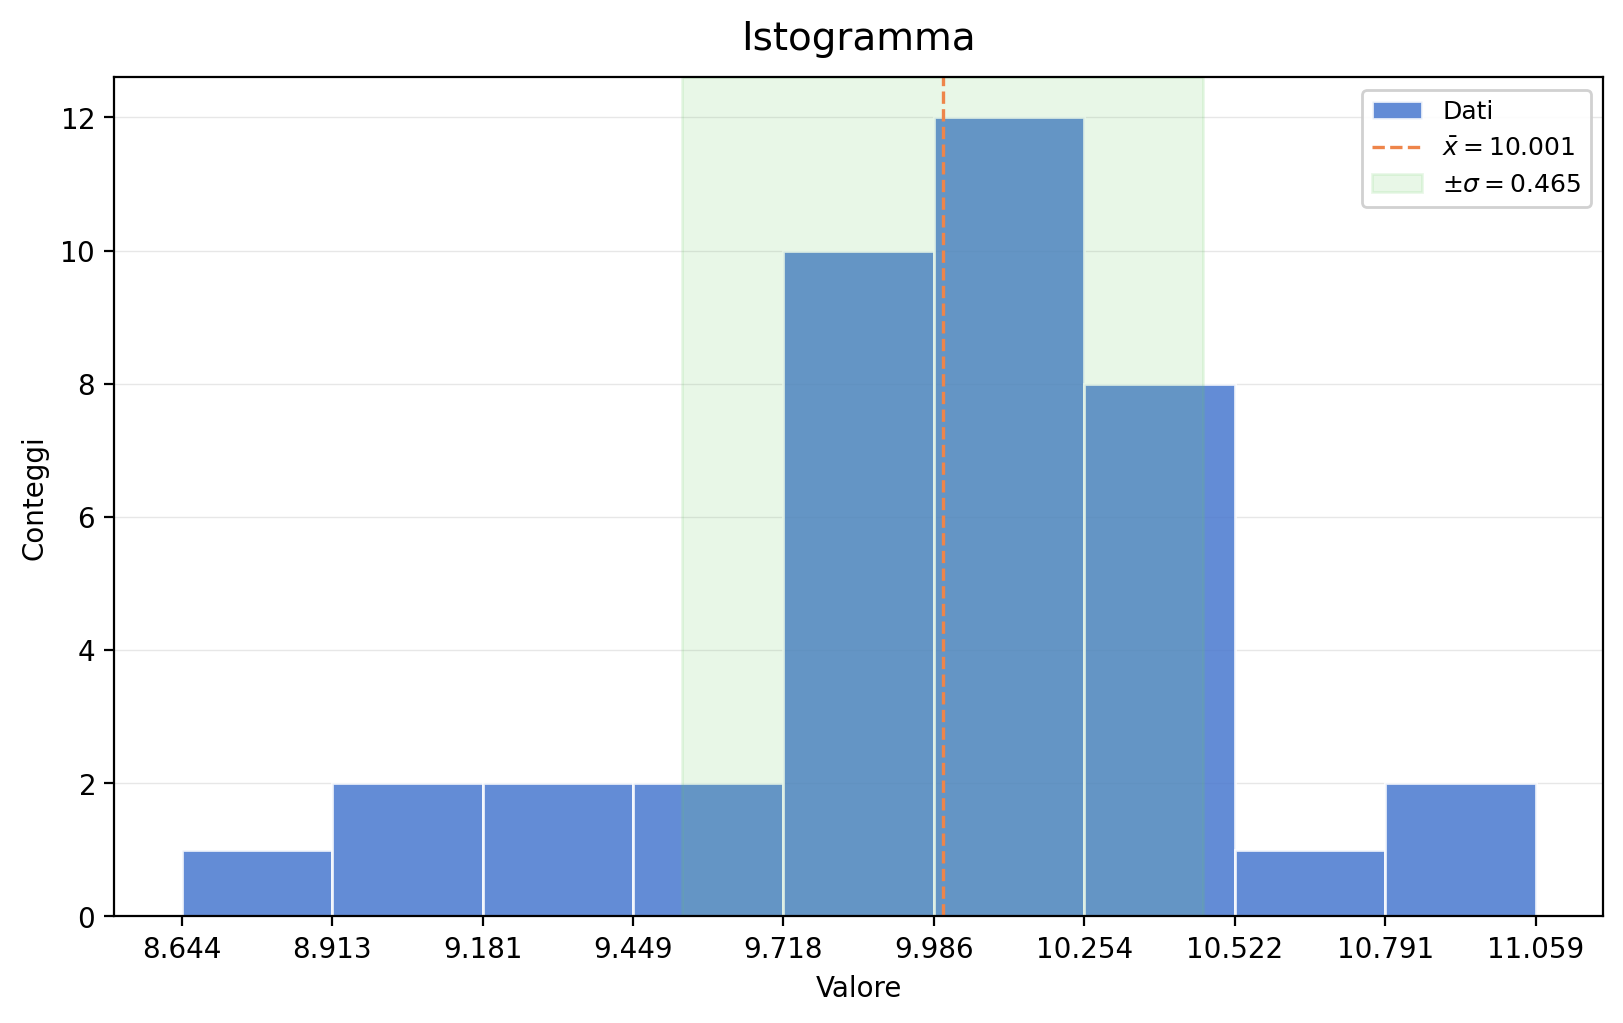

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram

rng = np.random.default_rng(seed=1)
x = rng.normal(loc=10.0, scale=0.5, size=40)

fig, ax = histogram(x)
plt.show()

#### Come leggere il grafico

- **Asse orizzontale.** Riporta i valori misurati. L'etichetta predefinita è `Valore`: la funzione non conosce la grandezza né la sua unità di misura, quindi tocca a te indicarle con `xlabel`.
- **Barre.** Ogni barra copre un bin. Le tacche sull'asse $x$ non sono tacche "tonde": sono proprio i bordi dei bin, scritti con tre decimali (`decimals=3`). La larghezza dei bin, circa $0.27$, è stata scelta automaticamente da `bins="auto"`.
- **Asse verticale.** Con il valore predefinito `stat="count"` l'altezza di una barra è il numero $n_i$ di misure nel bin: ad esempio 12 misure cadono tra $9.986$ e $10.254$. L'etichetta `Conteggi` è scelta automaticamente in base a `stat`.
- **Linea tratteggiata.** È la media aritmetica di tutte le 40 misure, $\bar{x} = 10.001$, riportata anche in legenda.
- **Banda verde.** Si estende da $\bar{x} - \sigma$ a $\bar{x} + \sigma$, con $\sigma = 0.465$. Con il valore predefinito `ddof=0`, $\sigma$ è calcolata dividendo per $N$, non per $N-1$.
- **Testi predefiniti.** Titolo `Istogramma`, etichetta dei dati `Dati` e asse `Valore` sono segnaposto in italiano: nei grafici da consegnare vanno sostituiti.

#### Che cosa non si può concludere

I dati sono stati generati da una gaussiana con media $10$ e deviazione standard $0.5$, ma l'istogramma non lo "dimostra": con 40 misure la stessa figura sarebbe compatibile con molte altre distribuzioni simmetriche. Anche la piccola differenza tra $\sigma = 0.465$ e il valore vero $0.5$ è normale: è una fluttuazione dovuta alla dimensione finita del campione.

:::{admonition} Da ricordare
:class: mx-takeaway

Basta `histogram(x)` per vedere la forma dei dati, ma i testi predefiniti sono segnaposto: un grafico scientifico ha sempre grandezza e unità sull'asse $x$.
:::

(hist-examples)=
## Esempi guidati

Gli esempi seguono un percorso: dalla lettura di un singolo istogramma alla scelta dei bin, dalle normalizzazioni fino ai problemi tipici dei dati reali. Ogni blocco di codice è completo: puoi copiarlo in un notebook o in uno script ed eseguirlo così com'è. I dati simulati usano sempre un seme fisso, quindi ottieni gli stessi numeri e gli stessi grafici.

Le stringhe dentro i grafici usano simboli e codice invece di parole, così la stessa figura vale per la versione italiana e per quella inglese di questa pagina. Le etichette automatiche dell'asse $y$, come `Conteggi`, restano in italiano perché sono quelle prodotte da `histogram`.

(hist-ex-pendulum)=
### Misure ripetute del periodo di un pendolo

Un pendolo semplice lungo circa mezzo metro oscilla con un periodo di circa $1.42\ \mathrm{s}$. Supponiamo di misurarlo 50 volte con una fotocellula: le piccole variazioni casuali dell'apparato rendono ogni misura leggermente diversa. Simuliamo questo esperimento con misure gaussiane di media $1.420\ \mathrm{s}$ e deviazione standard $0.010\ \mathrm{s}$.

Rispetto al primo esempio diamo un nome alla grandezza e alla sua unità, scegliamo simboli coerenti per la legenda e usiamo `ddof=1`. Con `ddof=1` la banda mostra la **deviazione standard campionaria** $s$, che divide per $N-1$: è la stima usata di solito quando la media è calcolata dagli stessi dati. Per coerenza la banda viene chiamata $\pm s$.

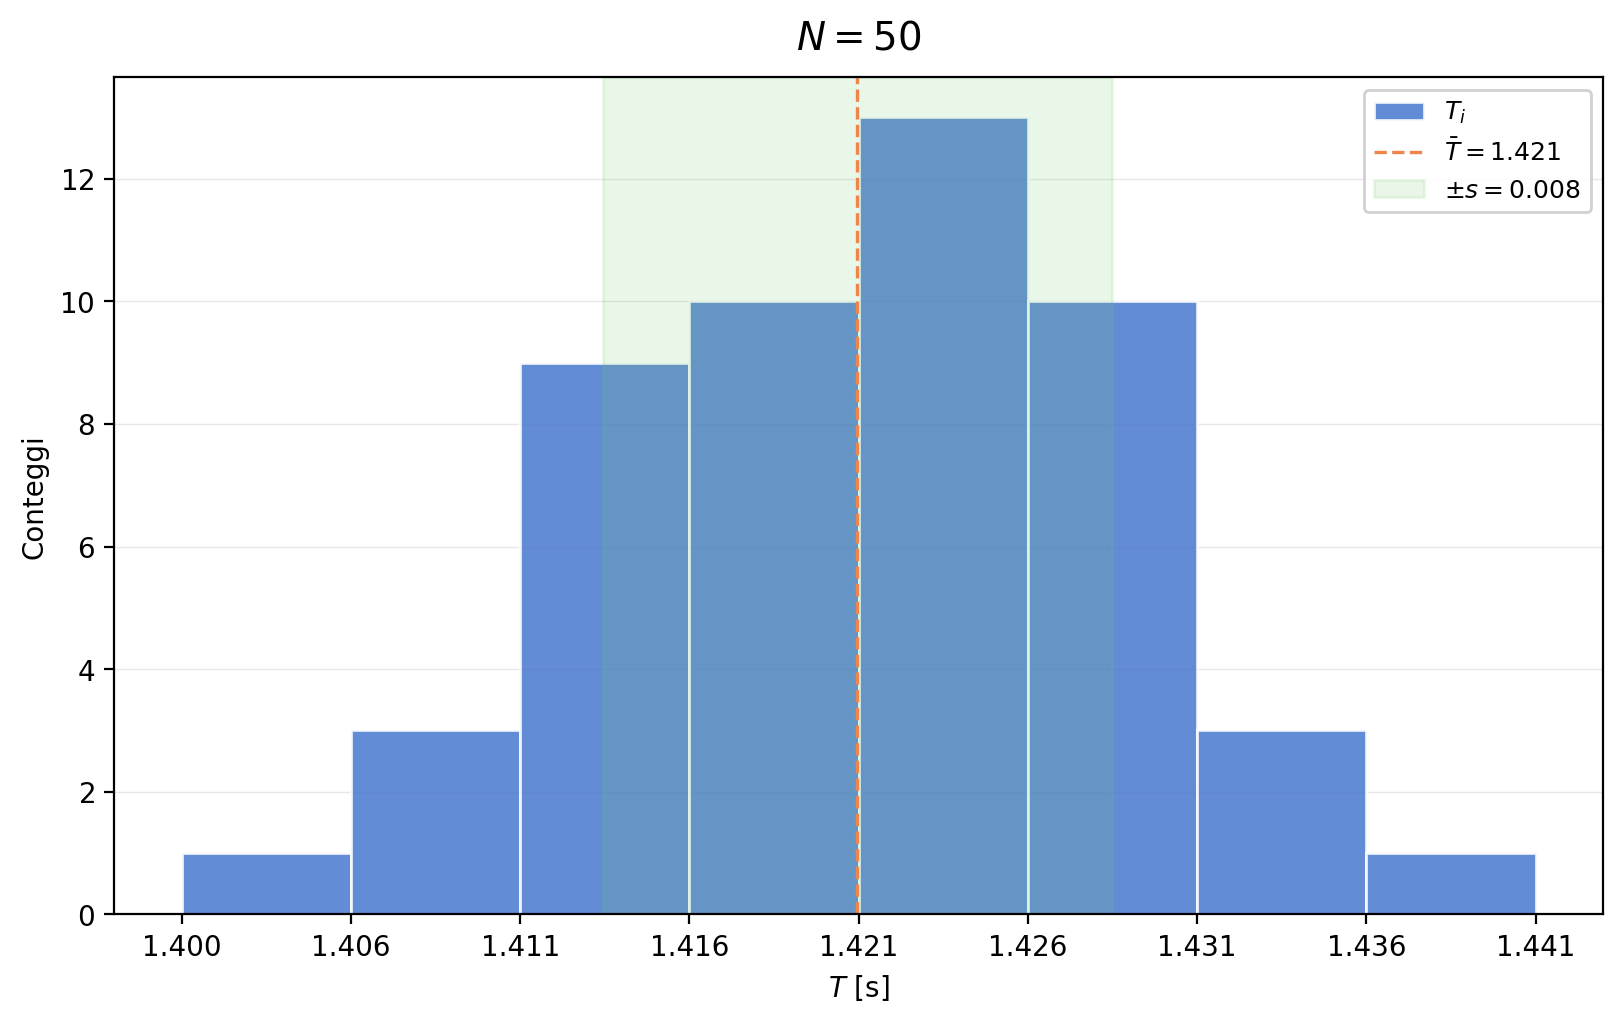

64%


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram

rng = np.random.default_rng(seed=42)
T = rng.normal(loc=1.420, scale=0.010, size=50)

fig, ax = histogram(
    T,
    ddof=1,
    label=r"$T_i$",
    xlabel=r"$T$ [s]",
    title=r"$N = 50$",
    mean_symbol=r"\bar{T}",
    band_symbol=r"\pm s",
    decimals=3,
)
plt.show()

inside = np.mean(np.abs(T - T.mean()) < T.std(ddof=1))
print(f"{inside:.0%}")

#### Come leggere il grafico

La distribuzione è a campana e quasi simmetrica attorno alla media $\bar{T} = 1.421\ \mathrm{s}$: le misure si addensano nei bin centrali, con 13 valori nel bin più alto, e diventano rare allontanandosi dal centro. La banda verde copre l'intervallo $\bar{T} \pm s$, con $s = 0.008\ \mathrm{s}$.

La riga stampata sotto il grafico, calcolata con NumPy e non da `histogram`, dice che il 64% delle misure cade dentro la banda. Per una distribuzione gaussiana ci si aspetta circa il 68%: con sole 50 misure, uno scarto di qualche punto percentuale è del tutto normale.

#### Che cosa non si può concludere

La banda **non** è l'incertezza sul periodo. La deviazione standard $s$ descrive quanto è dispersa una *singola* misura; l'incertezza sulla media di $N$ misure indipendenti è molto più piccola, $s/\sqrt{N} \approx 0.008/\sqrt{50} \approx 0.001\ \mathrm{s}$, e `histogram` non la calcola. Inoltre la deviazione standard misura solo gli effetti casuali: un errore sistematico, ad esempio una fotocellula in ritardo di qualche millisecondo, sposta tutte le misure insieme e non è visibile nell'istogramma.

:::{admonition} Da ricordare
:class: mx-takeaway

La banda $\pm s$ descrive la dispersione delle singole misure, non l'incertezza della media: quest'ultima è $s/\sqrt{N}$ e va calcolata a parte.
:::

<span id="personalizzazione-bins"></span>
(hist-ex-bins)=
### Quanti bin?

La scelta dei bin è la decisione più importante quando costruisci un istogramma, perché cambia ciò che il grafico lascia vedere. Prendiamo 200 misure del periodo e disegniamole tre volte, cambiando solo `bins`: 4 bin, la regola automatica predefinita e 60 bin.

Per confrontare i pannelli creiamo una figura con tre assi e passiamo ciascun asse a `histogram` con `ax=`. Attiviamo lo stile `mespy` per tutta la figura con `plt.style.use("mespy")`, togliamo banda e legenda per lasciare spazio alle barre e disattiviamo le tacche sui bordi dei bin, che con 60 bin si sovrapporrebbero.

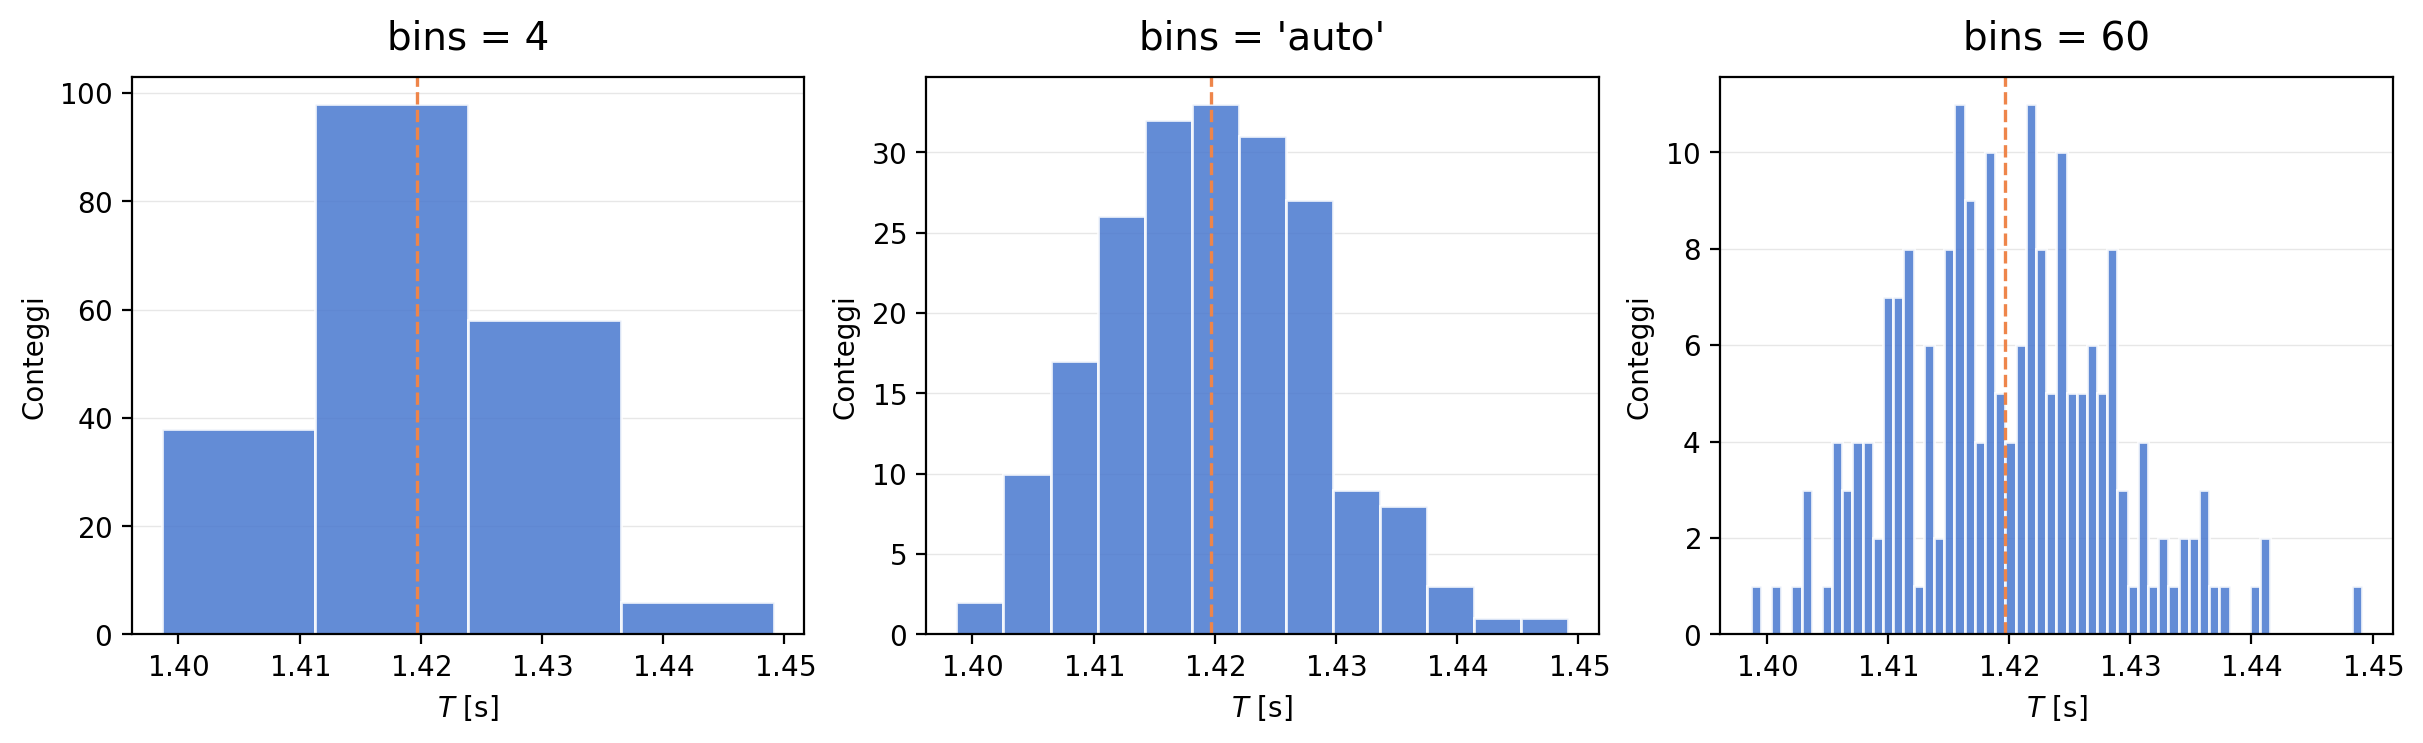

13


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram

plt.style.use("mespy")

rng = np.random.default_rng(seed=42)
T = rng.normal(loc=1.420, scale=0.010, size=200)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, bins in zip(axes, [4, "auto", 60]):
    histogram(
        T,
        bins=bins,
        ax=ax,
        xlabel=r"$T$ [s]",
        title=f"bins = {bins!r}",
        show_bin_ticks=False,
        show_band=False,
        show_legend=False,
    )
plt.show()

print(len(np.histogram_bin_edges(T, bins="auto")) - 1)

#### Come leggere il grafico

- **4 bin (sinistra).** I bin sono troppo larghi: ognuno raccoglie misure molto diverse tra loro. Il grafico dice soltanto che i valori sono concentrati attorno a $1.42\ \mathrm{s}$; la forma a campana è persa e la barra più alta non è nemmeno centrata sulla media.
- **`"auto"` (centro).** NumPy ha scelto 13 bin, il numero stampato sotto il grafico. La forma a campana è chiara e le irregolarità tra bin vicini sono piccole rispetto all'altezza delle barre.
- **60 bin (destra).** I bin sono così stretti che ognuno contiene poche misure. L'altezza delle barre salta da un bin all'altro e compaiono bin vuoti: è rumore statistico, non struttura fisica dei dati.

Anche l'asse verticale cambia. Con `stat="count"` l'altezza dipende dalla larghezza dei bin: un bin largo raccoglie più misure, quindi i conteggi massimi passano da circa 100 a circa 10. Per confrontare istogrammi con bin diversi servono le normalizzazioni dell'esempio [Conteggi, frequenze relative e densità](#hist-ex-stat).

La regola `"auto"` di NumPy sceglie la larghezza dei bin a partire dal numero di dati e dalla loro dispersione, prendendo il risultato migliore tra le regole di Sturges e di Freedman–Diaconis. È un buon punto di partenza, non una scelta ottimale per ogni esperimento. Puoi passare a `bins` anche gli altri nomi accettati da `numpy.histogram_bin_edges`, come `"fd"`, `"sturges"` o `"sqrt"`.

#### Che cosa non si può concludere

Nessuno dei tre pannelli è "quello vero". Picchi o buchi che compaiono solo con una certa scelta dei bin non vanno interpretati come proprietà fisiche finché non sopravvivono a scelte ragionevoli diverse.

:::{admonition} Da ricordare
:class: mx-takeaway

Troppi pochi bin nascondono la forma, troppi la riempiono di rumore. Prova sempre più di una scelta prima di trarre conclusioni.
:::

(hist-ex-bin-width)=
### Larghezza e bordi dei bin

Spesso è più naturale scegliere la **larghezza** dei bin invece del loro numero, ad esempio un multiplo della risoluzione dello strumento o un valore tondo. Con `bin_width` la funzione costruisce i bordi da sola, allineandoli a multipli interi della larghezza scelta.

Qui usiamo bin larghi $5\ \mathrm{ms}$ sulle stesse 200 misure. Lasciamo attive le tacche sui bordi (`show_bin_ticks=True`, il valore predefinito) e le ruotiamo di 45° con `tick_rotation` per non sovrapporle. Dopo il grafico stampiamo il minimo e il massimo dei dati e i bordi usati: poiché le tacche coincidono con i bordi, `ax.get_xticks()` li restituisce.

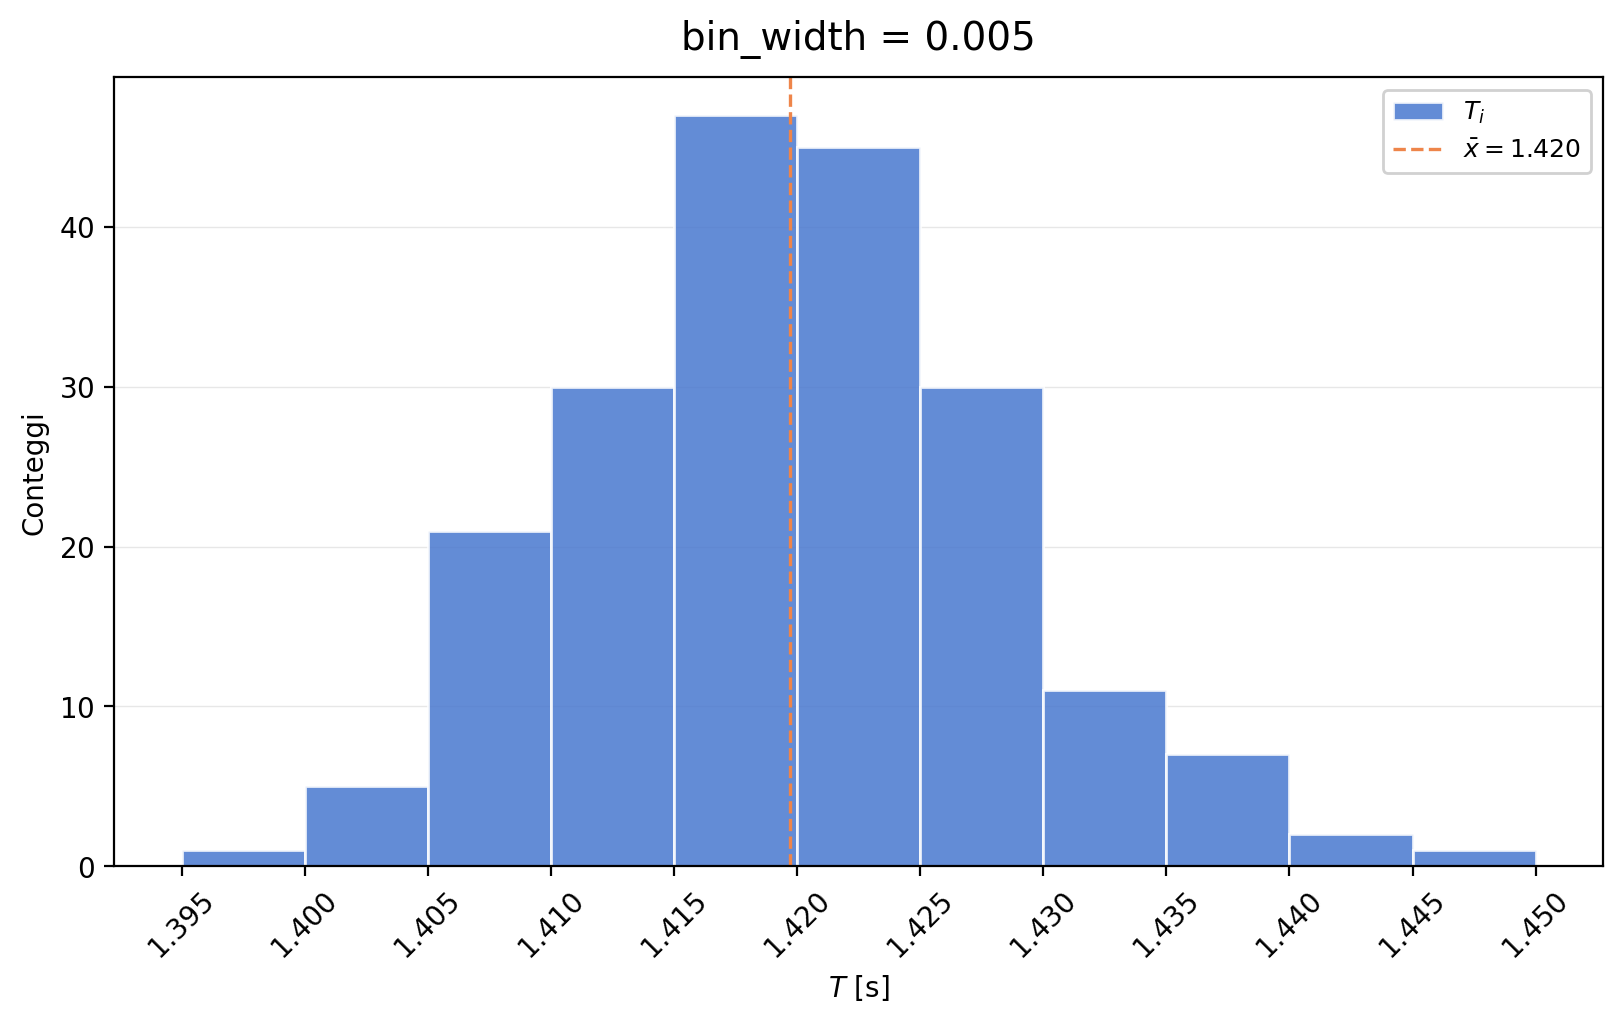

1.3986795371926868 1.4491386246600733
[1.395 1.4   1.405 1.41  1.415 1.42  1.425 1.43  1.435 1.44  1.445 1.45 ]


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram

rng = np.random.default_rng(seed=42)
T = rng.normal(loc=1.420, scale=0.010, size=200)

fig, ax = histogram(
    T,
    bin_width=0.005,
    label=r"$T_i$",
    xlabel=r"$T$ [s]",
    title="bin_width = 0.005",
    tick_rotation=45,
    show_band=False,
)
plt.show()

print(T.min(), T.max())
print(ax.get_xticks())

#### Come leggere il grafico

I dati vanno da $1.3987$ a $1.4491\ \mathrm{s}$. La funzione ha arrotondato il primo bordo per difetto e l'ultimo per eccesso al multiplo di $0.005$ più vicino: i bordi vanno da $1.395$ a $1.450$, e tutte le misure sono contenute negli 11 bin. Le tacche ruotate sono esattamente questi bordi, quindi puoi leggere sul grafico l'intervallo coperto da ogni barra.

Con bordi tondi l'istogramma è più facile da descrivere a parole: "47 misure tra $1.415$ e $1.420\ \mathrm{s}$". Ogni bin include il bordo sinistro ed esclude il destro, tranne l'ultimo, che include entrambi.

Quando ti serve il pieno controllo, ad esempio per usare gli stessi bin in più grafici o per calcolare i conteggi con NumPy, passa direttamente l'array dei bordi: `bins=np.linspace(1.395, 1.445, 11)` crea 10 bin larghi $0.005$ tra $1.395$ e $1.445$. È ciò che fanno i prossimi esempi.

#### Che cosa non si può concludere

Una larghezza tonda non è automaticamente una larghezza adatta. Se è più piccola della risoluzione dello strumento, compaiono bin vuoti alternati a bin pieni; l'esempio [Dati reali con risoluzione finita](#hist-ex-real-data) mostra che cosa succede.

:::{admonition} Da ricordare
:class: mx-takeaway

`bin_width` dà bordi tondi e facili da leggere; un array esplicito di bordi dà il controllo completo ed è riutilizzabile in altri calcoli.
:::

(hist-ex-stat)=
### Conteggi, frequenze relative e densità

Il parametro `stat` decide che cosa rappresenta l'altezza di una barra. Chiamiamo $n_i$ il numero di osservazioni nel bin $i$, $\Delta x_i$ la sua larghezza e $N = \sum_i n_i$ il numero di osservazioni contenute nei bin:

| `stat` | Altezza $h_i$ | Unità | Somma che vale 1 |
| --- | --- | --- | --- |
| `"count"` | $n_i$ | nessuna, è un numero di misure | nessuna: $\sum_i h_i = N$ |
| `"probability"` | $n_i / N$ | adimensionale | $\sum_i h_i = 1$ |
| `"density"` | $n_i / (N\,\Delta x_i)$ | inverso dell'unità di $x$ | $\sum_i h_i\,\Delta x_i = 1$ |

Nella densità conta l'**area** delle barre: $h_i\,\Delta x_i = n_i/N$ è la frazione di misure nel bin $i$. Disegniamo le tre rappresentazioni con gli stessi bordi e scriviamo la formula di ciascuna come etichetta dell'asse $y$.

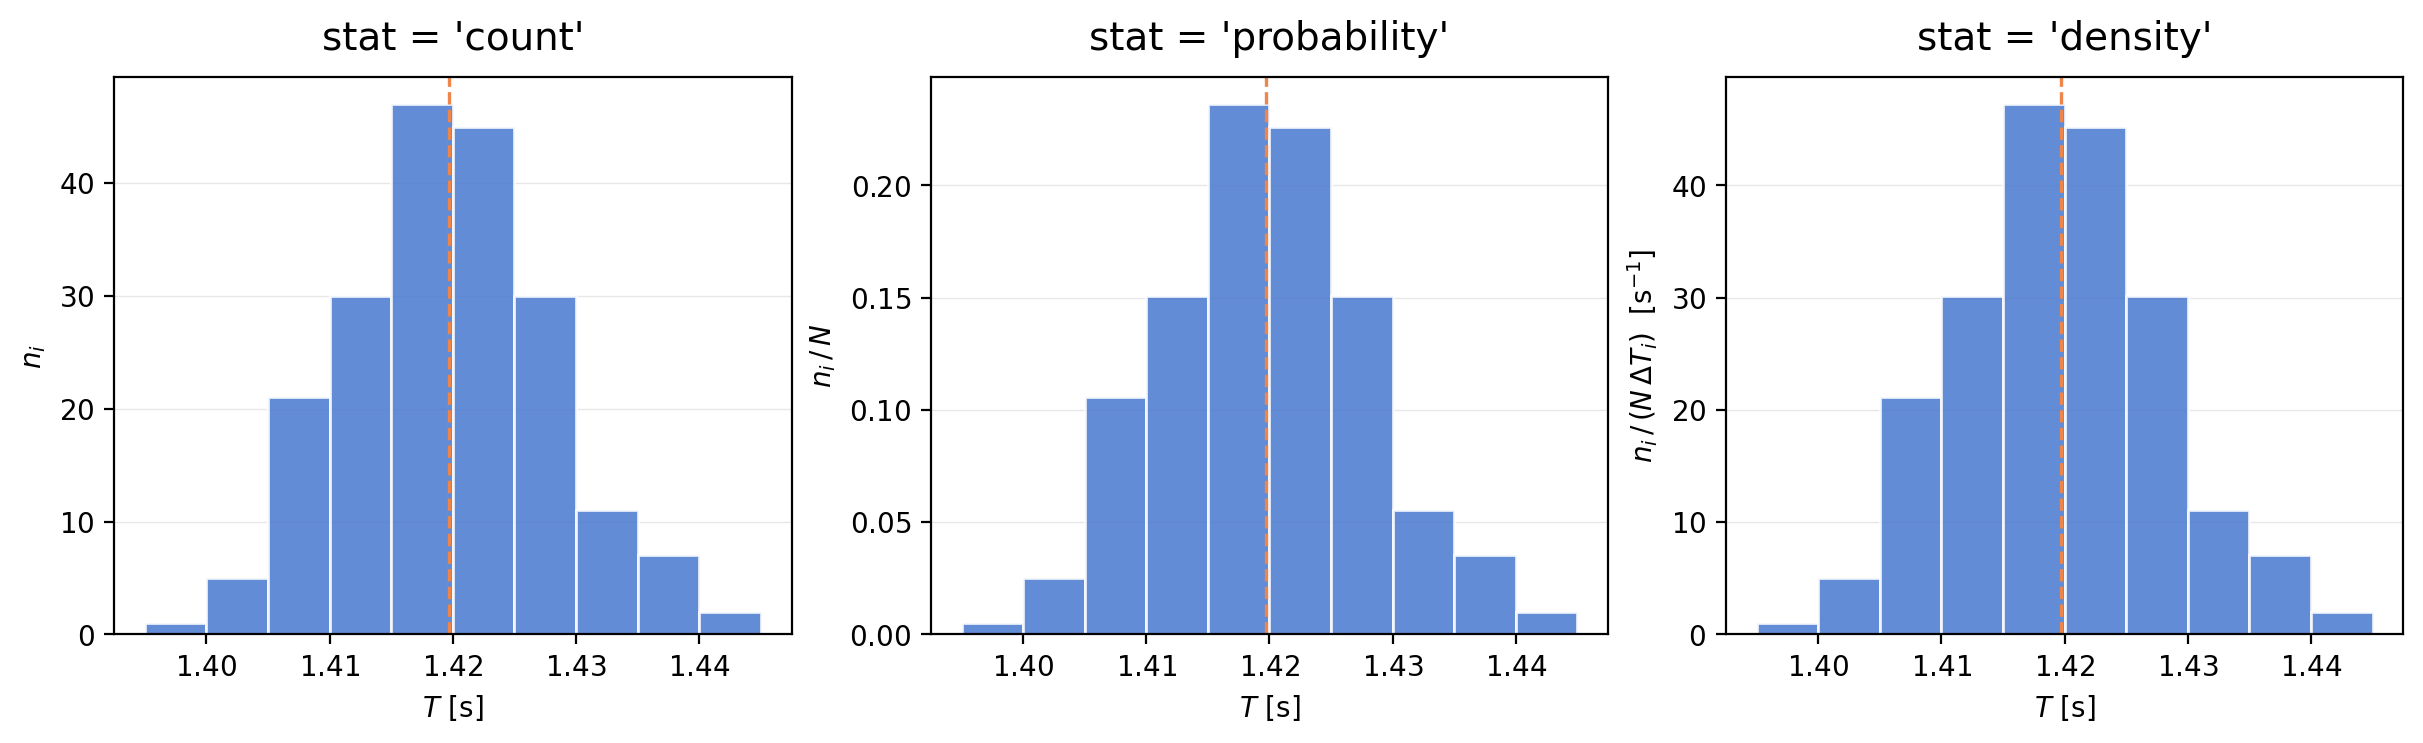

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram

plt.style.use("mespy")

rng = np.random.default_rng(seed=42)
T = rng.normal(loc=1.420, scale=0.010, size=200)
edges = np.linspace(1.395, 1.445, 11)

ylabels = {
    "count": r"$n_i$",
    "probability": r"$n_i \,/\, N$",
    "density": r"$n_i \,/\, (N\,\Delta T_i)$  [s$^{-1}$]",
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (stat, ylabel) in zip(axes, ylabels.items()):
    histogram(
        T,
        stat,
        bins=edges,
        ax=ax,
        xlabel=r"$T$ [s]",
        ylabel=ylabel,
        title=f"stat = {stat!r}",
        show_bin_ticks=False,
        show_band=False,
        show_legend=False,
    )
plt.show()

La forma delle tre figure è identica: cambia solo la scala verticale. `histogram` non restituisce le altezze delle barre, ma possiamo ricalcolarle con `numpy.histogram` usando gli stessi bordi e verificare le proprietà della tabella. Questa cella continua la precedente e ne usa le variabili `T` ed `edges`.

In [7]:
counts, _ = np.histogram(T, bins=edges)
widths = np.diff(edges)
N = counts.sum()

probability = counts / N
density = counts / (N * widths)

print(T.size, N)
print(probability.sum())
print((density * widths).sum())
print(density.max())

200 199
1.0
1.0
47.23618090452362


#### Come leggere il grafico

- **Sinistra, conteggi.** La barra più alta contiene 47 misure. È la rappresentazione più diretta, ma dipende sia dal numero di misure sia dalla larghezza dei bin.
- **Centro, frequenze relative.** La stessa barra vale circa $0.24$: contiene il 24% delle misure nei bin. Le altezze sono numeri puri e, come conferma la seconda riga stampata, sommano a 1.
- **Destra, densità.** La barra più alta vale circa $47\ \mathrm{s^{-1}}$: è una densità per unità di periodo e può superare 1 senza alcun problema. Moltiplicata per la larghezza $0.005\ \mathrm{s}$ restituisce di nuovo $0.24$. La terza riga stampata conferma che l'area totale vale 1.

La prima riga stampata contiene un dettaglio importante: le misure sono 200, ma solo 199 cadono nei bin. Il valore massimo, $1.4491\ \mathrm{s}$, è oltre l'ultimo bordo, $1.445$. Le normalizzazioni dividono per $N = 199$, mentre la linea della media usa tutte le 200 misure.

#### Che cosa non si può concludere

Una densità di $47\ \mathrm{s^{-1}}$ non è una probabilità, e la densità dell'istogramma non coincide con la densità di probabilità della distribuzione da cui provengono i dati: ne è una stima, soggetta a fluttuazioni statistiche e alla scelta dei bin.

:::{admonition} Da ricordare
:class: mx-takeaway

Conteggi per descrivere il campione, frequenze relative per confrontare campioni di dimensione diversa, densità quando i bin hanno larghezze diverse.
:::

(hist-ex-unequal)=
### Bin di larghezza diversa

Un contatore Geiger registra eventi casuali, e il tempo $t$ che passa tra un evento e il successivo segue una distribuzione esponenziale: gli intervalli brevi sono i più frequenti, quelli lunghi diventano via via più rari. Simuliamo 500 intervalli con un tempo medio di $40\ \mathrm{ms}$.

Poiché la coda della distribuzione è lunga e povera di dati, è ragionevole usare bin stretti dove ci sono molti dati e bin larghi nella coda. Scegliamo bordi la cui larghezza raddoppia: $0, 20, 40, 80, 160, 320\ \mathrm{ms}$. Disegniamo gli stessi dati in conteggi e in densità.

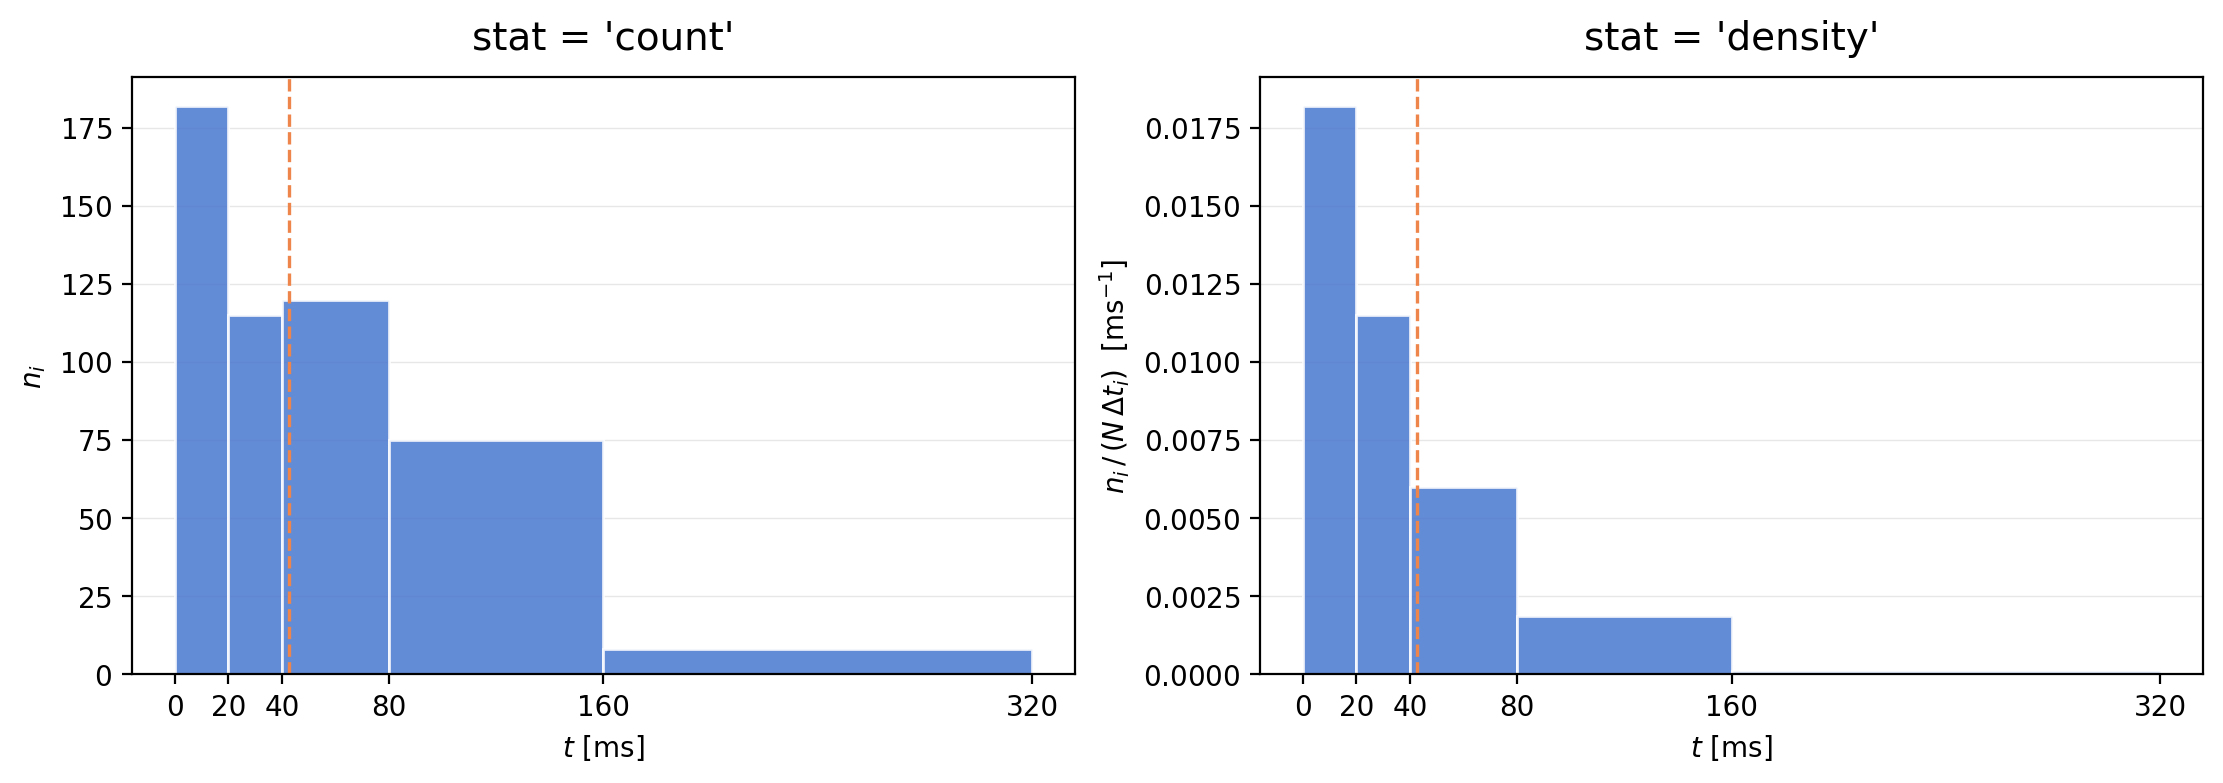

[182 115 120  75   8]


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram

plt.style.use("mespy")

rng = np.random.default_rng(seed=3)
t = rng.exponential(scale=40.0, size=500)
edges = [0, 20, 40, 80, 160, 320]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, stat, ylabel in [
    (axes[0], "count", r"$n_i$"),
    (axes[1], "density", r"$n_i \,/\, (N\,\Delta t_i)$  [ms$^{-1}$]"),
]:
    histogram(
        t,
        stat,
        bins=edges,
        ax=ax,
        xlabel=r"$t$ [ms]",
        ylabel=ylabel,
        title=f"stat = {stat!r}",
        decimals=0,
        show_band=False,
        show_legend=False,
    )
plt.show()

print(np.histogram(t, bins=edges)[0])

#### Come leggere il grafico

A sinistra, in conteggi, i bin larghi sembrano importanti quanto quelli stretti. I conteggi stampati sotto il grafico sono 182, 115, 120, 75 e 8: il bin tra 40 e $80\ \mathrm{ms}$ contiene più misure di quello tra 20 e $40\ \mathrm{ms}$ solo perché è largo il doppio, e il bin tra 80 e $160\ \mathrm{ms}$ ne contiene 75 perché è largo $80\ \mathrm{ms}$. Letto così, l'istogramma suggerirebbe che la distribuzione resti quasi costante tra 20 e $80\ \mathrm{ms}$, che è falso.

A destra, in densità, ogni conteggio è diviso per la larghezza del proprio bin. Le altezze diminuiscono in modo regolare da un bin all'altro, come ci si aspetta da un esponenziale: la densità torna a descrivere quanto sono probabili i valori *per unità di tempo*, indipendentemente da come hai scelto i bin. L'ultimo bin, tra 160 e $320\ \mathrm{ms}$, ha una densità così bassa da essere appena visibile.

La linea della media è a circa $40\ \mathrm{ms}$, vicina al tempo medio usato nella simulazione. In una distribuzione asimmetrica come questa la media non coincide con il valore più frequente, che è vicino a zero.

#### Che cosa non si può concludere

Con bin di larghezza diversa l'altezza in conteggi o in frequenza relativa non è confrontabile da un bin all'altro. Anche in densità, i bin larghi della coda contengono poche misure e la loro altezza ha un'incertezza relativa grande.

:::{admonition} Da ricordare
:class: mx-takeaway

Con bin di larghezza diversa usa sempre `stat="density"`: è l'area delle barre, non l'altezza, a rappresentare la frazione di misure.
:::

(hist-ex-shapes)=
### Distribuzioni diverse, stessa banda

La banda $\bar{x} \pm s$ ha sempre lo stesso aspetto, ma il suo significato dipende dalla forma della distribuzione. Confrontiamo tre campioni di 2000 valori:

- una **distribuzione uniforme** tra $-0.5$ e $0.5$, come l'errore di arrotondamento di uno strumento digitale espresso in unità della sua risoluzione;
- una **distribuzione gaussiana** standard, tipica degli errori casuali che sono la somma di molti piccoli contributi;
- una **distribuzione esponenziale** con media 1, come i tempi di attesa dell'esempio precedente.

Usiamo `stat="density"` per confrontare le forme e calcoliamo con NumPy la frazione di valori che cade dentro la banda.

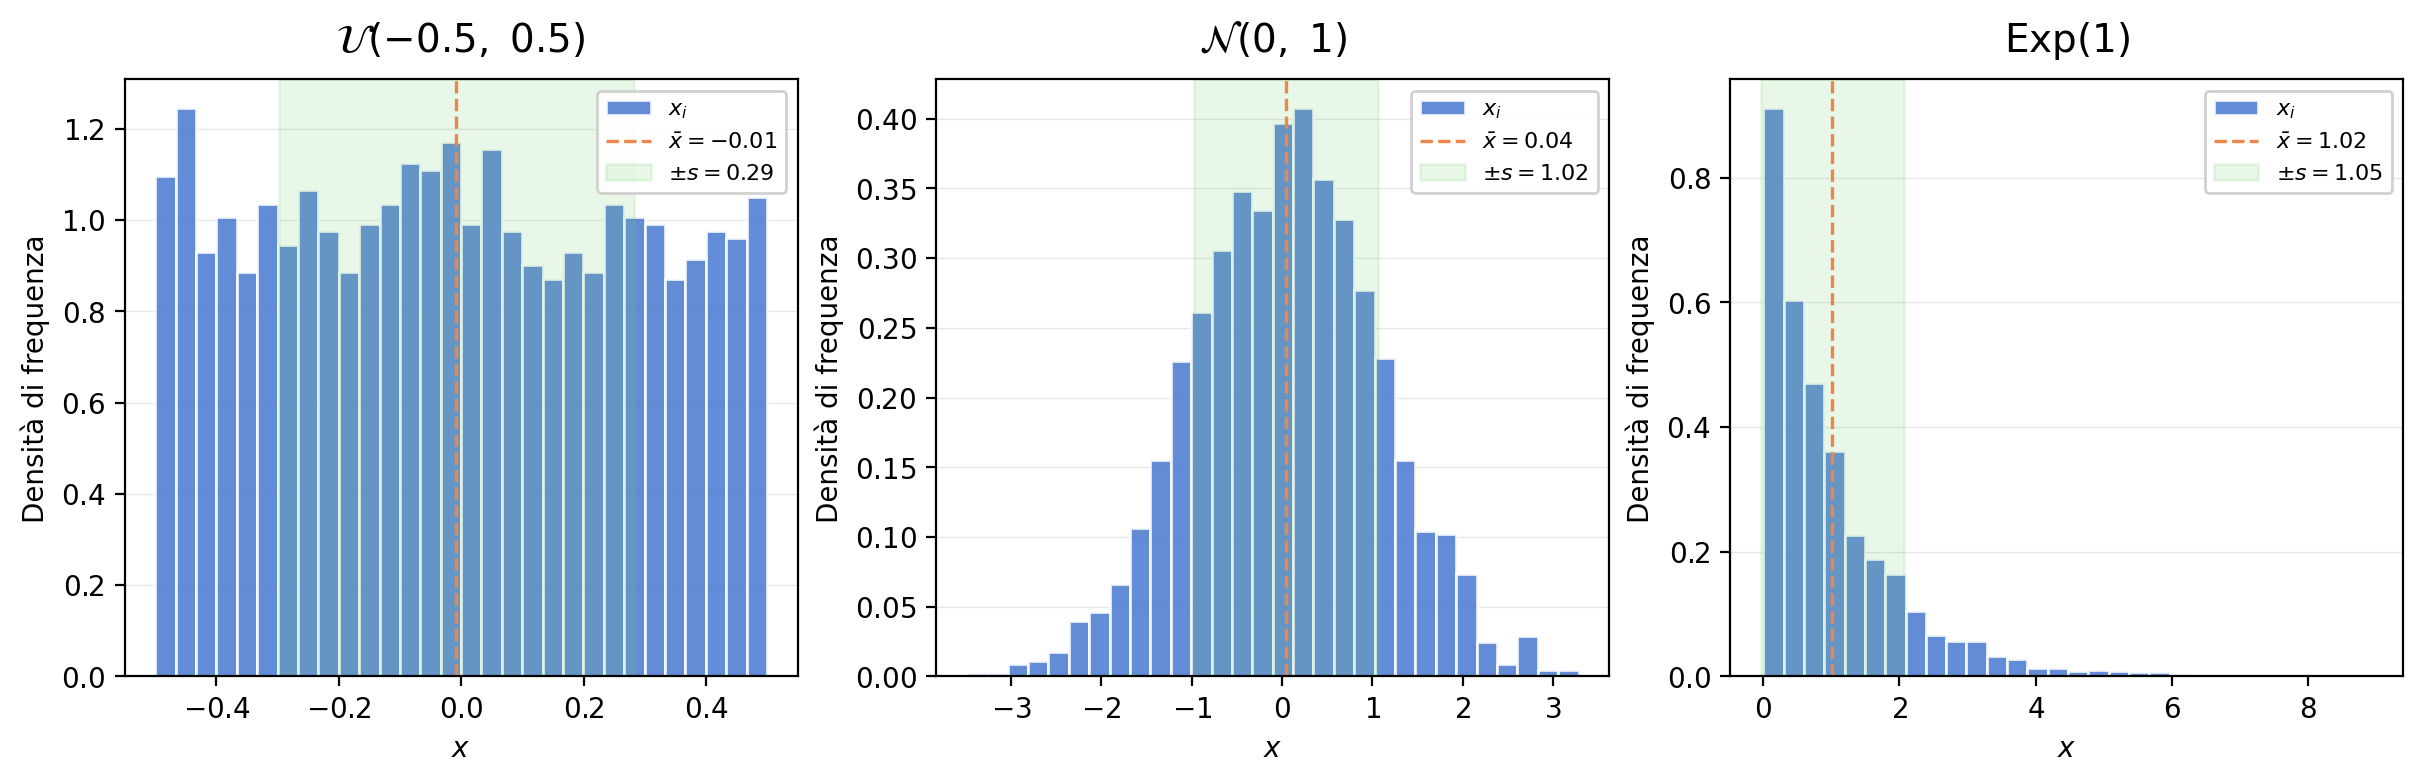

$\mathcal{U}(-0.5,\ 0.5)$    57.5%
$\mathcal{N}(0,\ 1)$         68.2%
$\mathrm{Exp}(1)$            87.1%


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram

plt.style.use("mespy")

rng = np.random.default_rng(seed=5)
samples = {
    r"$\mathcal{U}(-0.5,\ 0.5)$": rng.uniform(-0.5, 0.5, size=2000),
    r"$\mathcal{N}(0,\ 1)$": rng.normal(0.0, 1.0, size=2000),
    r"$\mathrm{Exp}(1)$": rng.exponential(1.0, size=2000),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (title, x) in zip(axes, samples.items()):
    histogram(
        x,
        "density",
        bins=30,
        ddof=1,
        ax=ax,
        label=r"$x_i$",
        xlabel=r"$x$",
        title=title,
        band_symbol=r"\pm s",
        decimals=2,
        show_bin_ticks=False,
        legend_fontsize=8,
    )
plt.show()

for title, x in samples.items():
    inside = np.mean(np.abs(x - x.mean()) < x.std(ddof=1))
    print(f"{title:28} {inside:.1%}")

#### Come leggere il grafico

- **Uniforme.** Le barre formano un altopiano irregolare attorno a 1, il valore della densità teorica $1/(b-a)$. La banda copre circa il 58% dei valori; per una uniforme il valore teorico è $1/\sqrt{3} \approx 57.7\%$.
- **Gaussiana.** La banda copre il 68.2% dei valori, in accordo con il 68.3% teorico.
- **Esponenziale.** La distribuzione è fortemente asimmetrica e la banda copre l'87% dei valori; il valore teorico è $1 - e^{-2} \approx 86.5\%$. La banda si estende anche a sinistra dello zero, dove non ci sono dati: i tempi di attesa non possono essere negativi.

#### Che cosa non si può concludere

La regola "il 68% dei dati cade entro una deviazione standard" vale per la gaussiana, non per ogni distribuzione. E poiché media e deviazione standard riassumono solo posizione e dispersione, due campioni con gli stessi $\bar{x}$ e $s$ possono avere forme completamente diverse: per questo l'istogramma resta indispensabile.

:::{admonition} Da ricordare
:class: mx-takeaway

La banda $\pm s$ ha un significato probabilistico preciso solo se conosci la forma della distribuzione. Guarda sempre l'istogramma prima di interpretarla.
:::

(hist-ex-sample-size)=
### Quante misure servono?

Un istogramma costruito da poche misure può avere un aspetto molto diverso dalla distribuzione da cui provengono. Estraiamo tre campioni, di 20, 200 e 5000 valori, dalla **stessa** gaussiana del periodo e disegniamoli con gli stessi bordi. Usiamo `stat="density"`, così le altezze sono confrontabili anche se il numero di misure cambia, e fissiamo lo stesso intervallo verticale con `ylim`.

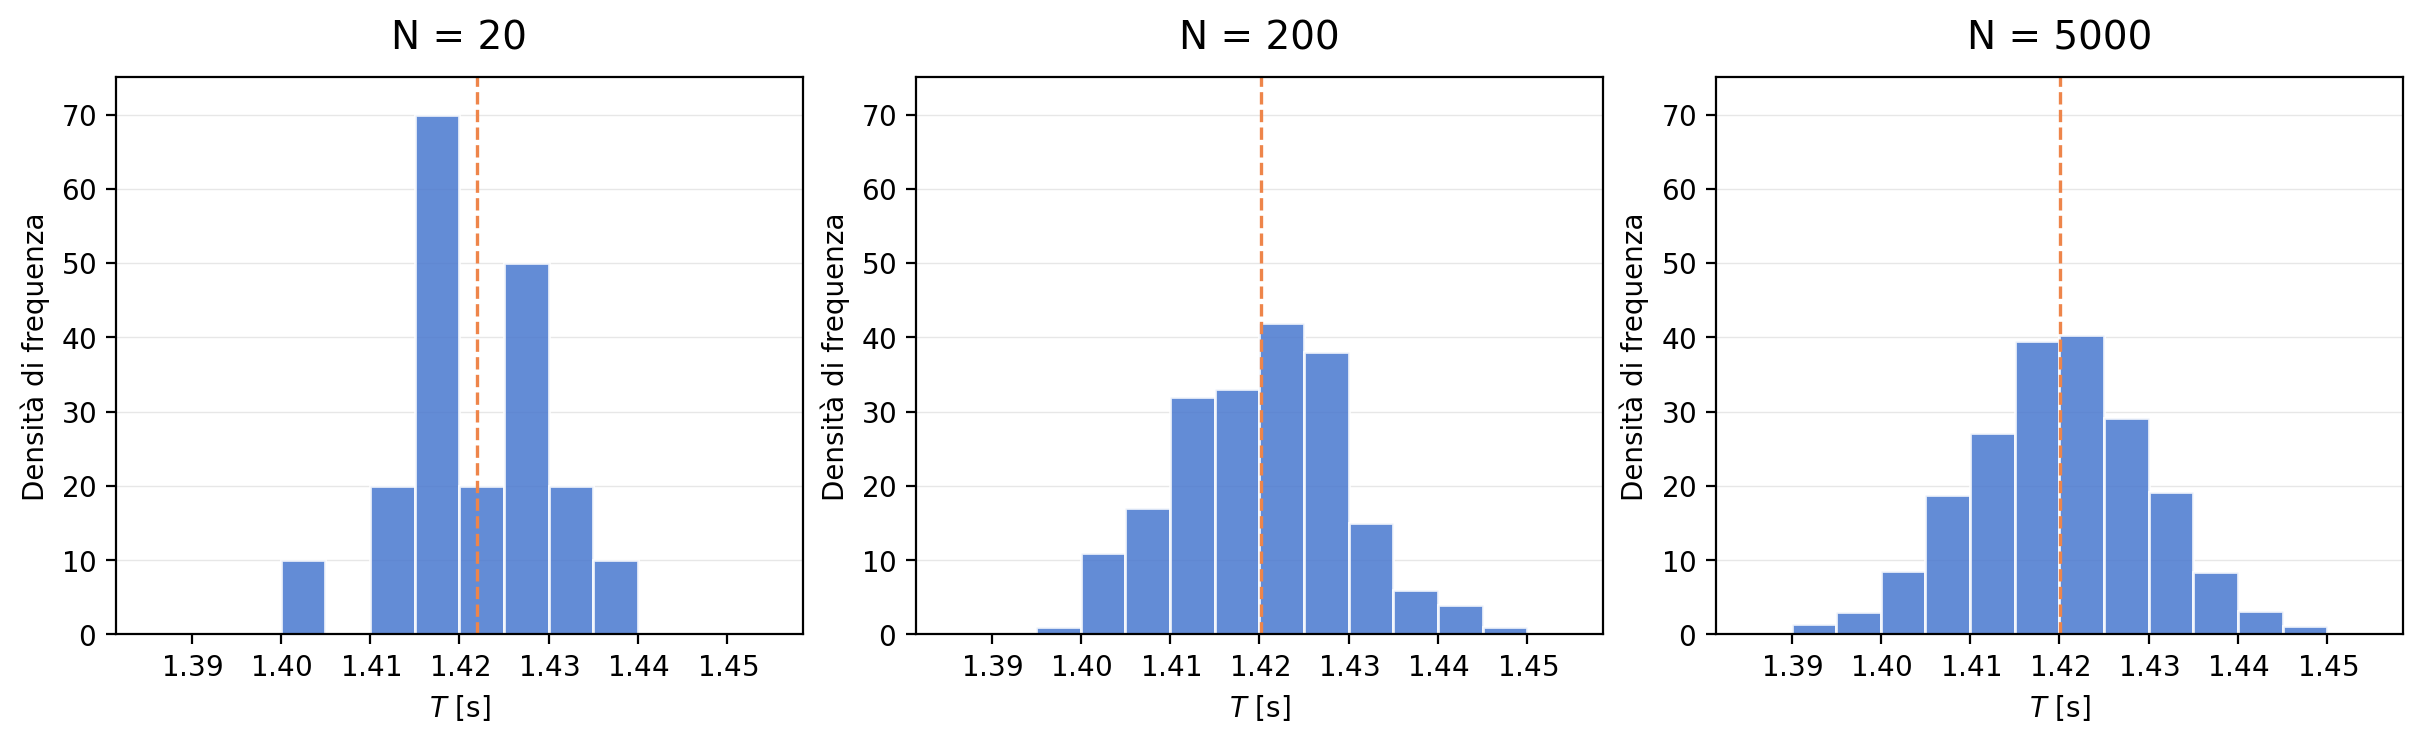

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram

plt.style.use("mespy")

rng = np.random.default_rng(seed=11)
edges = np.linspace(1.385, 1.455, 15)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, n in zip(axes, [20, 200, 5000]):
    T = rng.normal(loc=1.420, scale=0.010, size=n)
    histogram(
        T,
        "density",
        bins=edges,
        ax=ax,
        xlabel=r"$T$ [s]",
        title=f"N = {n}",
        ylim=(0, 75),
        show_bin_ticks=False,
        show_band=False,
        show_legend=False,
    )
plt.show()

#### Come leggere il grafico

Con 20 misure (sinistra) l'istogramma è irregolare: un bin isolato, un buco, due picchi separati. Nessuno di questi dettagli è una proprietà del pendolo: la distribuzione da cui provengono i dati è la stessa nei tre pannelli. Con 200 misure (centro) compare la forma a campana, ancora con qualche irregolarità. Con 5000 misure (destra) il profilo è regolare e il massimo si avvicina al valore teorico $1/(\sigma\sqrt{2\pi}) \approx 40\ \mathrm{s^{-1}}$.

Il motivo è statistico. Il numero di misure in un bin fluttua da un campione all'altro; se le misure sono indipendenti, la fluttuazione tipica di un conteggio $n_i$ è circa $\sqrt{n_i}$, quindi l'incertezza relativa è circa $1/\sqrt{n_i}$. Con 2 misure in un bin l'incertezza relativa è di circa il 70%; con 900 misure è di circa il 3%.

#### Che cosa non si può concludere

La forma di un istogramma non determina in modo univoco la distribuzione da cui provengono i dati, soprattutto con pochi dati. Con 20 misure non si può distinguere una gaussiana da una distribuzione con due picchi; anche con molti dati, distribuzioni diverse possono produrre istogrammi molto simili.

:::{admonition} Da ricordare
:class: mx-takeaway

Ogni barra ha un'incertezza statistica di circa $\sqrt{n_i}$ conteggi. Con pochi dati, interpreta solo le caratteristiche più marcate dell'istogramma.
:::

(hist-ex-discrete)=
### Dati discreti: conteggi di un rivelatore

Non tutte le grandezze sono continue. Se conti gli eventi registrati da un rivelatore in intervalli di 10 secondi, ottieni numeri interi $k = 0, 1, 2, \dots$, che per una sorgente stabile seguono una distribuzione di Poisson. Simuliamo 300 intervalli con una media di 3.2 eventi.

Per dati interi la scelta dei bordi è delicata. Confrontiamo la regola automatica con bordi posti a metà tra un intero e il successivo, $k \pm 0.5$, in modo che ogni bin contenga un solo valore possibile. Usiamo `stat="probability"`: l'altezza di ogni barra è la frazione di intervalli con quel numero di eventi.

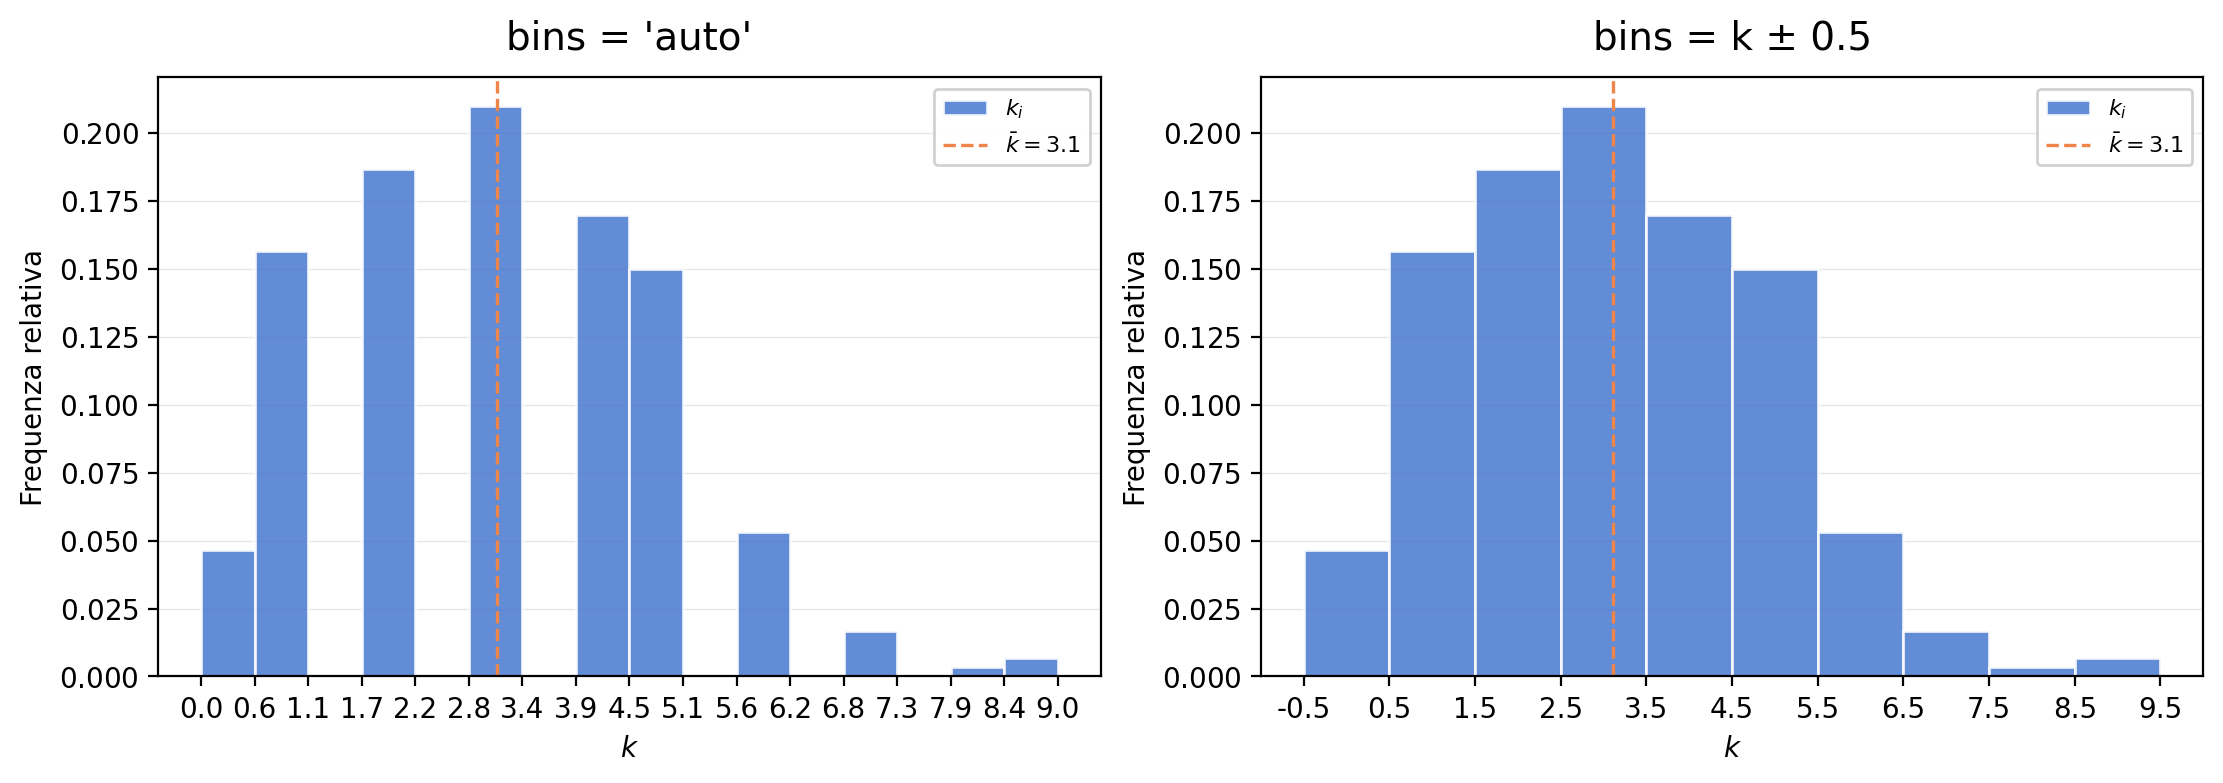

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([14, 47, 56, 63, 51, 45, 16,  5,  1,  2]))


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram

plt.style.use("mespy")

rng = np.random.default_rng(seed=7)
k = rng.poisson(lam=3.2, size=300)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, bins in [
    (axes[0], "auto"),
    (axes[1], np.arange(-0.5, k.max() + 1.5, 1.0)),
]:
    histogram(
        k,
        "probability",
        bins=bins,
        ax=ax,
        label=r"$k_i$",
        xlabel=r"$k$",
        mean_symbol=r"\bar{k}",
        title="bins = 'auto'" if isinstance(bins, str) else "bins = k ± 0.5",
        decimals=1,
        show_band=False,
        legend_fontsize=8,
    )
plt.show()

print(np.unique(k, return_counts=True))

#### Come leggere il grafico

- **Regola automatica (sinistra).** `histogram` converte i dati in numeri decimali e la regola `"auto"` sceglie 16 bin larghi circa $0.56$, più stretti della distanza tra due interi. Alcuni bin non contengono nessun intero e restano sempre vuoti: i buchi regolari sono un artefatto dei bin, non una proprietà della sorgente. Inoltre le barre non sono centrate sugli interi e la loro larghezza non ha alcun significato per dati contati.
- **Bordi a $k \pm 0.5$ (destra).** Ogni barra è centrata su un intero e contiene solo quel valore. Le tacche a $-0.5, 0.5, 1.5, \dots$ mostrano i bordi. La forma è quella attesa per una distribuzione di Poisson con media vicina a 3, e le altezze corrispondono alle frequenze stampate sotto il grafico: ad esempio 63 intervalli su 300, cioè 0.21, con $k = 3$.

#### Che cosa non si può concludere

La barra a $k = 9$ è più alta di quella a $k = 8$, ma sono rispettivamente 2 e 1 intervalli: con conteggi così piccoli la differenza è puro rumore statistico, non una proprietà della sorgente.

:::{admonition} Da ricordare
:class: mx-takeaway

Per dati interi usa bordi a metà tra gli interi, ad esempio `np.arange(-0.5, k.max() + 1.5, 1.0)`: ogni barra rappresenta un solo valore possibile.
:::

(hist-ex-real-data)=
### Dati reali con risoluzione finita

Il file [`test_misure.csv`](data/test_misure.csv), incluso nella documentazione, contiene 20 misure della lunghezza di un oggetto, in millimetri, prese con uno strumento di risoluzione $0.05\ \mathrm{mm}$. Lo carichiamo con `load_csv` di MesPy; per eseguire il codice scarica il file e mettilo in una cartella `data` accanto al notebook o allo script.

La risoluzione ha una conseguenza importante: i valori possibili non sono continui, ma multipli di $0.05\ \mathrm{mm}$. La prima riga stampata lo conferma: ci sono solo cinque valori distinti, da $25.20$ a $25.40\ \mathrm{mm}$. Confrontiamo tre scelte di bin: la regola automatica, `bin_width=0.05` e bordi espliciti a metà tra due valori possibili.

(array([25.2 , 25.25, 25.3 , 25.35, 25.4 ]), array([3, 4, 6, 5, 2]))


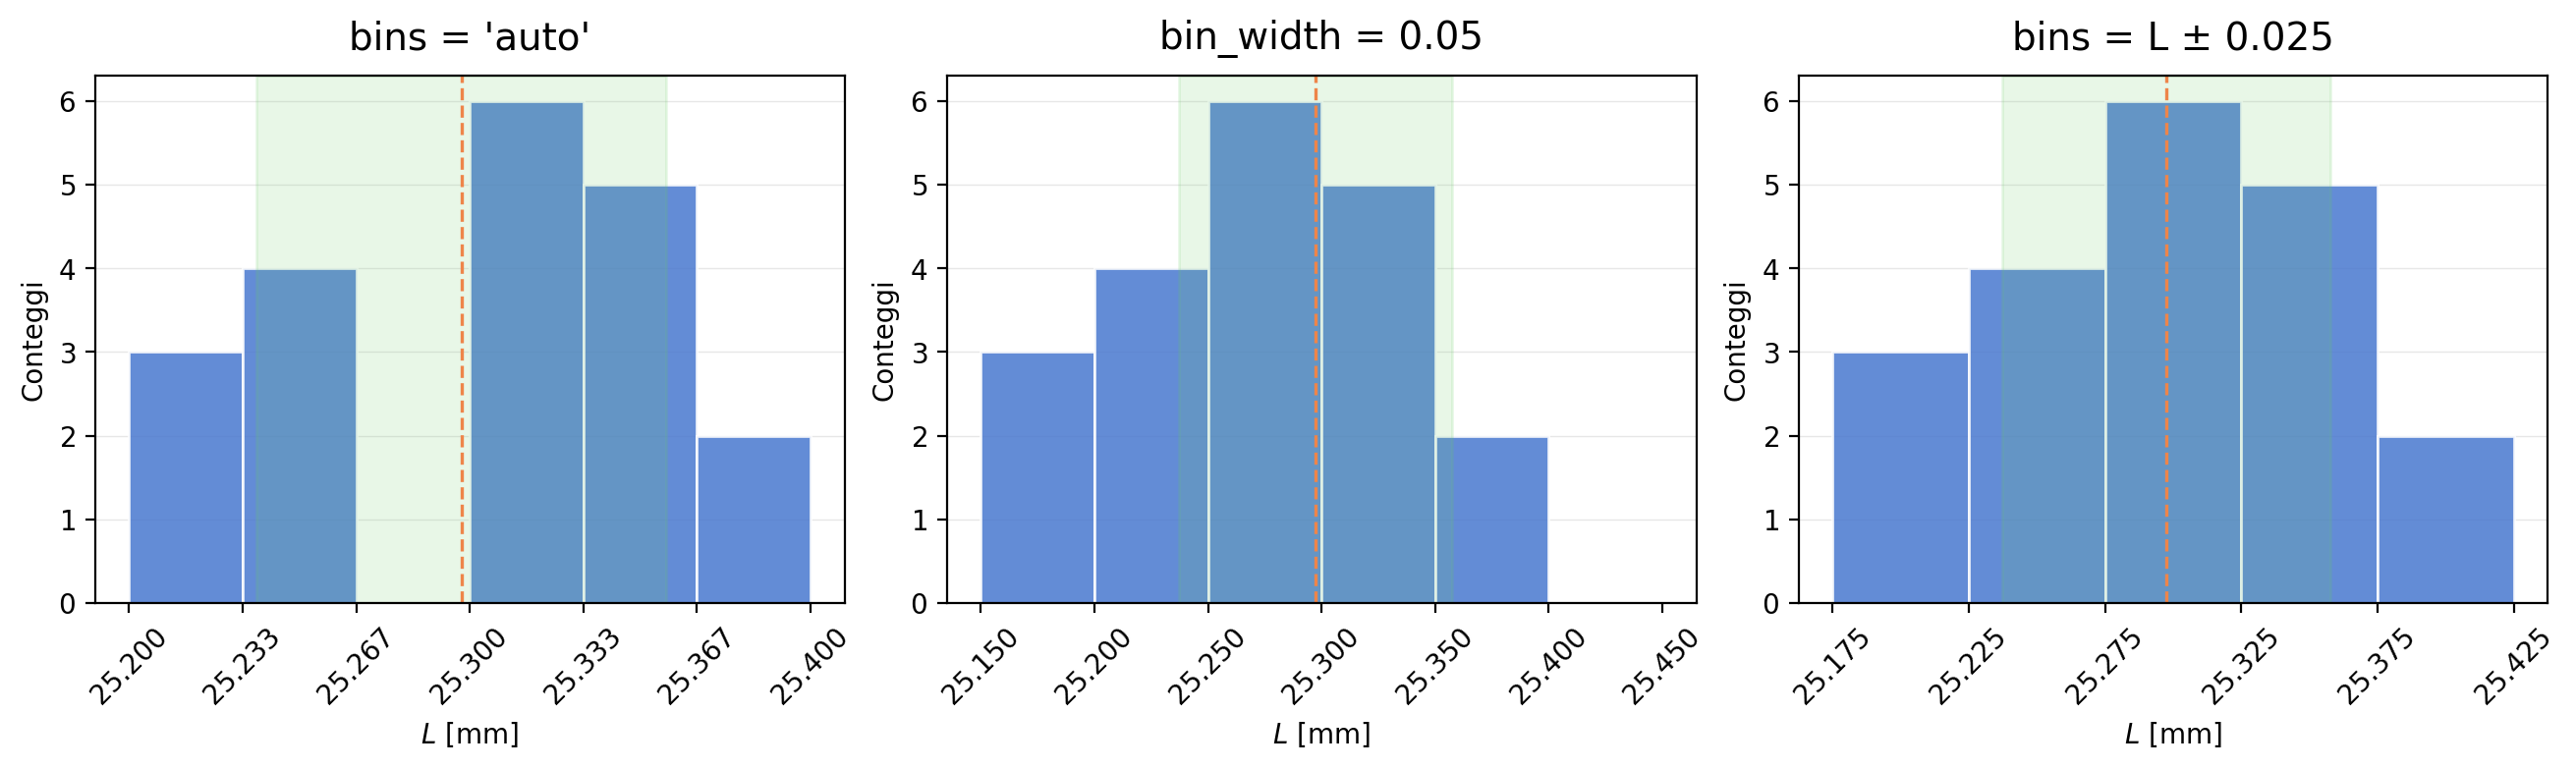

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram, load_csv

plt.style.use("mespy")

data = load_csv("data/test_misure.csv")
L = data["lunghezza_mm"]
print(np.unique(L, return_counts=True))

options = {
    "bins = 'auto'": {},
    "bin_width = 0.05": {"bin_width": 0.05},
    "bins = L ± 0.025": {"bins": np.arange(25.175, 25.45, 0.05)},
}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (title, binning) in zip(axes, options.items()):
    histogram(
        L,
        ax=ax,
        xlabel=r"$L$ [mm]",
        title=title,
        tick_rotation=45,
        show_legend=False,
        **binning,
    )
plt.show()

#### Come leggere il grafico

- **`bins="auto"` (sinistra).** La regola automatica sceglie 6 bin larghi circa $0.033\ \mathrm{mm}$, più stretti della risoluzione. Uno dei bin, tra $25.267$ e $25.300$, non contiene nessun valore possibile e resta vuoto. Il buco al centro della distribuzione sembra un fenomeno reale, ma è soltanto un artefatto dei bin.
- **`bin_width=0.05` (centro).** I bordi sono multipli di $0.05$, quindi coincidono con i valori misurati. Calcolati in virgola mobile, risultano leggermente più grandi dei valori tondi: ad esempio $25.200000000000003$ invece di $25.2$. Ogni misura finisce così nel bin *a sinistra* del proprio valore: le 6 misure da $25.30\ \mathrm{mm}$ formano la barra tra $25.25$ e $25.30$, e l'ultimo bin resta vuoto. La linea della media, a $25.2975\ \mathrm{mm}$, cade proprio su un bordo invece che al centro della barra più alta.
- **Bordi a metà (destra).** Con `bins=np.arange(25.175, 25.45, 0.05)` ogni bin è centrato su un valore possibile: 3, 4, 6, 5 e 2 misure, come nella prima riga stampata. È l'unica delle tre rappresentazioni fedele ai dati.

#### Che cosa non si può concludere

Con 20 misure e soli cinque valori distinti, l'istogramma non permette di giudicare la forma della distribuzione: è compatibile con una gaussiana, ma anche con molte altre distribuzioni. Inoltre, quando la dispersione delle misure è confrontabile con la risoluzione, come qui, $s$ non descrive solo la variabilità dell'oggetto misurato ma anche la discretizzazione dello strumento.

:::{admonition} Da ricordare
:class: mx-takeaway

Con dati quantizzati scegli bin larghi quanto la risoluzione, o un suo multiplo, e con i bordi a metà tra due valori possibili: mai bordi che coincidono con i valori misurati.
:::

(hist-ex-outlier)=
### Un dato anomalo: escludere dal grafico non esclude dalla statistica

Durante una serie di 30 misure del periodo, una volta il cronometro viene fermato in ritardo e il quaderno di laboratorio riporta il problema: la misura registrata è $1.520\ \mathrm{s}$, lontana da tutte le altre. Vediamo tre modi di disegnare questi dati:

1. tutte le misure, senza accorgimenti;
2. tutte le misure, limitando i bin all'intervallo plausibile con `hist_range=(1.39, 1.45)`;
3. le misure senza il dato anomalo, che è l'ultimo dell'array, quindi `T[:-1]`.

Questa volta lasciamo la legenda, perché i valori numerici di media e banda sono il punto dell'esempio.

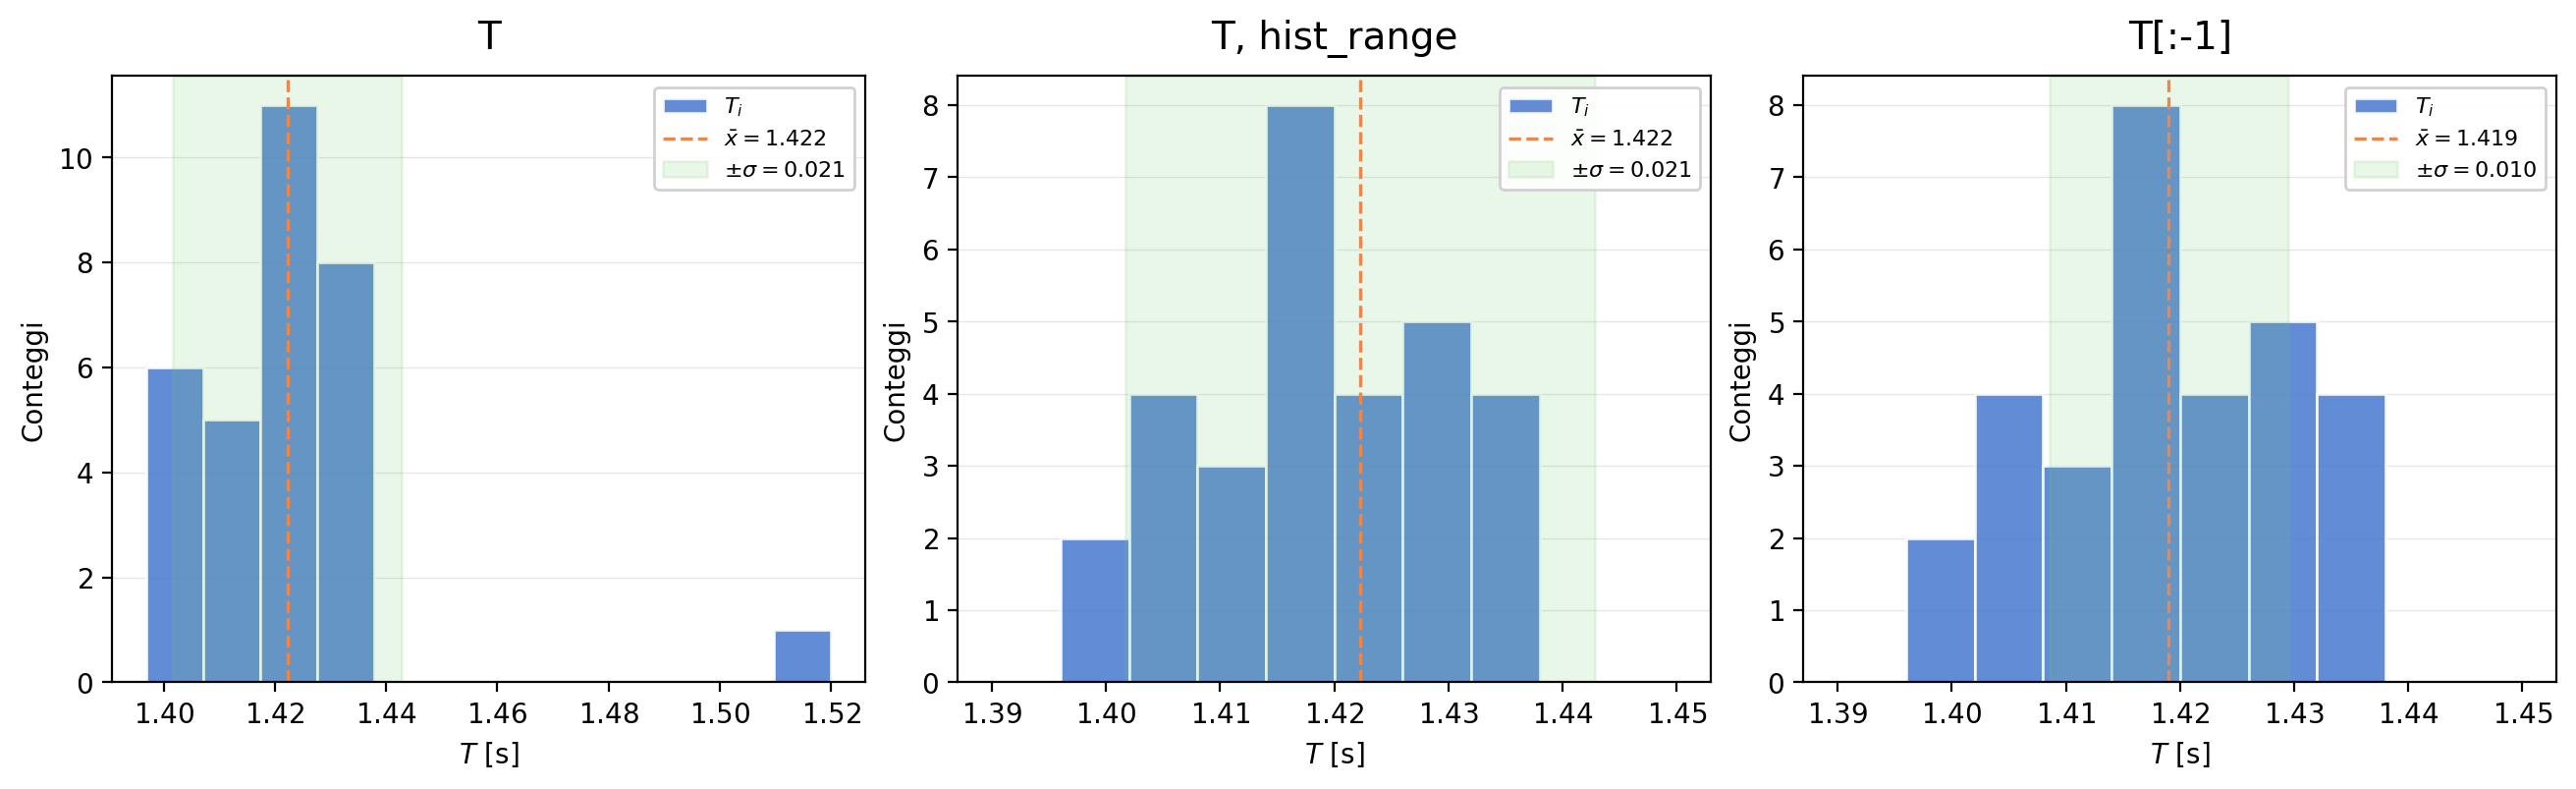

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram

plt.style.use("mespy")

rng = np.random.default_rng(seed=8)
T = np.append(rng.normal(loc=1.420, scale=0.010, size=30), 1.520)

common = dict(label=r"$T_i$", xlabel=r"$T$ [s]", show_bin_ticks=False, legend_fontsize=8)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
histogram(T, ax=axes[0], title="T", **common)
histogram(T, ax=axes[1], title="T, hist_range", hist_range=(1.39, 1.45), **common)
histogram(T[:-1], ax=axes[2], title="T[:-1]", hist_range=(1.39, 1.45), **common)
plt.show()

#### Come leggere il grafico

- **Tutte le misure (sinistra).** Il dato anomalo allarga l'intervallo dei dati, quindi i bin automatici diventano larghi e la distribuzione principale è schiacciata in poche barre a sinistra. La misura isolata a $1.52\ \mathrm{s}$ è ben visibile: è proprio così che un istogramma aiuta a scoprire gli errori grossolani.
- **Con `hist_range` (centro).** Le barre sembrano pulite, perché il dato anomalo è fuori dall'intervallo e non entra nei bin. La legenda però dice altro: la media è ancora $1.422\ \mathrm{s}$ e $\sigma = 0.021\ \mathrm{s}$, e la banda verde è molto più larga della distribuzione disegnata. Media e $\sigma$ sono calcolate su tutto il campione, anomalia compresa.
- **Dato rimosso (destra).** Senza la misura anomala la media scende a $1.419\ \mathrm{s}$ e $\sigma$ si dimezza, $0.010\ \mathrm{s}$: ora banda e barre raccontano la stessa storia.

Lo stesso vale per `xlim`: restringere l'asse $x$ nasconde il dato anomalo alla vista, ma non cambia né i bin né la statistica.

#### Che cosa non si può concludere

Un valore non si scarta perché è scomodo o lontano dagli altri. Qui la rimozione è giustificata da un problema documentato durante la misura; senza una causa nota, scartare dati altera il risultato e va almeno dichiarato e motivato nella relazione.

:::{admonition} Da ricordare
:class: mx-takeaway

`hist_range` e `xlim` cambiano ciò che vedi, non ciò che calcoli. Per escludere un dato dalla statistica, rimuovilo dal campione, e solo con una buona ragione.
:::

<span id="personalizzazione-labels-e-legenda"></span>
<span id="confronto-su-due-assi"></span>
(hist-ex-style)=
### Aspetto, composizione e salvataggio

Per una relazione il grafico deve essere leggibile anche stampato e coerente con le altre figure. Tutti i parametri estetici di `histogram` agiscono solo sulla chiamata in cui li passi. In questo esempio usiamo bordi espliciti, testi con simboli e unità, colori personalizzati per barre, media e banda, legenda in alto a sinistra, una griglia più marcata e dimensioni della figura adatte a una pagina.

I colori si scrivono in uno dei formati accettati da Matplotlib: un nome come `"black"`, un codice esadecimale come `"#2d4f7c"` o un riferimento al ciclo di colori dello stile come `"C1"`.

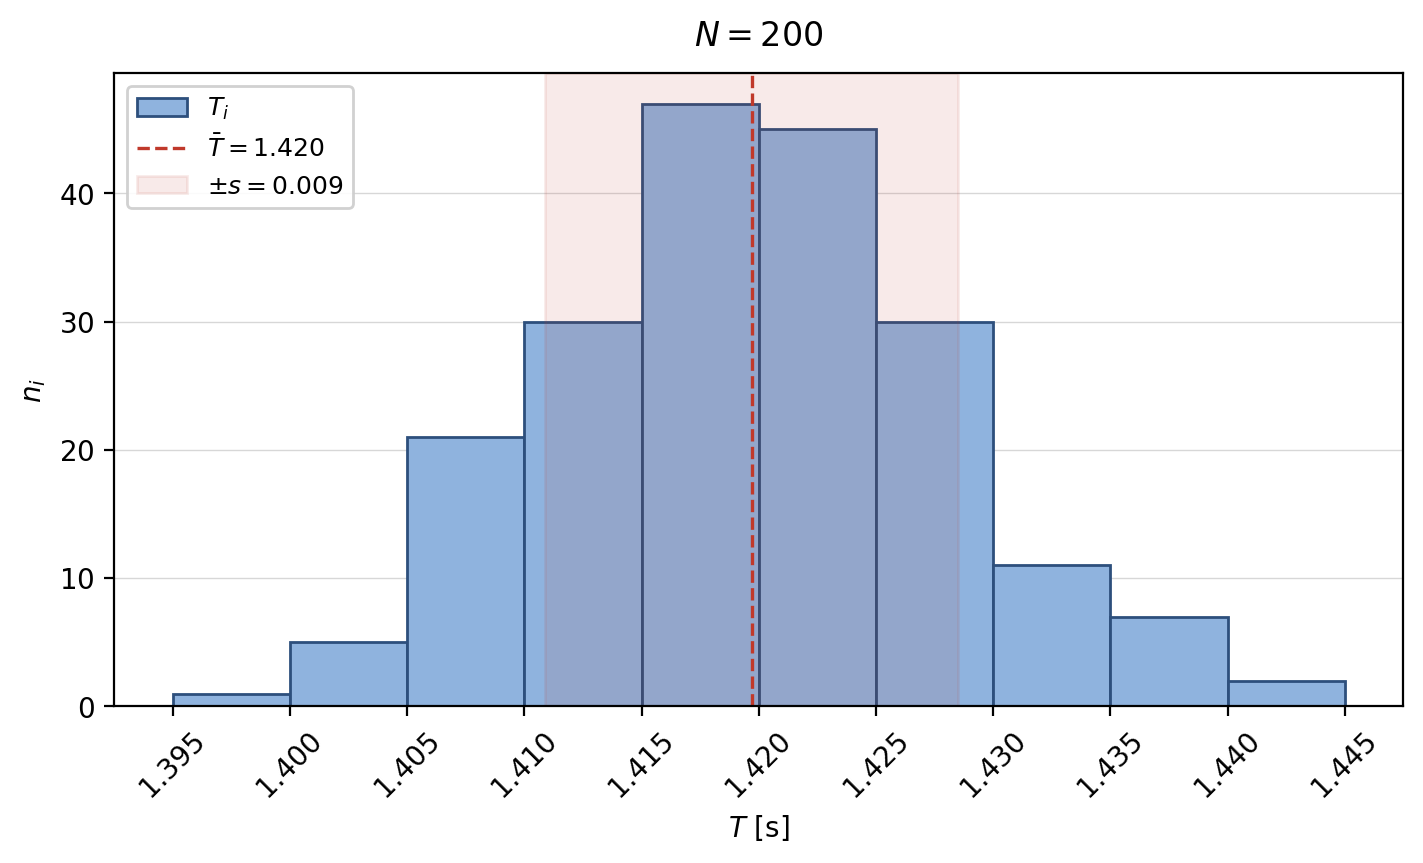

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from mespy import histogram

rng = np.random.default_rng(seed=42)
T = rng.normal(loc=1.420, scale=0.010, size=200)

fig, ax = histogram(
    T,
    bins=np.linspace(1.395, 1.445, 11),
    ddof=1,
    label=r"$T_i$",
    xlabel=r"$T$ [s]",
    ylabel=r"$n_i$",
    title=r"$N = 200$",
    mean_symbol=r"\bar{T}",
    band_symbol=r"\pm s",
    decimals=3,
    bar_color="#8fb3de",
    edgecolor="#2d4f7c",
    hist_alpha=1.0,
    mean_color="#c0392b",
    band_color="#c0392b",
    band_alpha=0.10,
    tick_rotation=45,
    legend_loc="upper left",
    title_fontsize=12,
    grid_alpha=0.5,
    figsize=(7, 4.2),
)
plt.show()

#### Come leggere il grafico

Le barre hanno un bordo scuro e sono completamente opache (`hist_alpha=1.0`), quindi restano distinguibili anche in una stampa in bianco e nero. Linea della media e banda condividono lo stesso colore, così la legenda le associa visivamente. Le etichette dei bordi sono ruotate di 45° e scritte con tre decimali (`decimals=3`), che controlla anche le cifre di $\bar{T}$ e $s$ in legenda. La griglia orizzontale ha opacità $0.5$ grazie a `grid_alpha`.

**Comporre più grafici.** Negli esempi precedenti hai visto il procedimento: crei la figura e gli assi con `plt.subplots(...)`, passi ogni asse a `histogram` con `ax=` e, se vuoi lo stile `mespy` anche per gli assi creati da te, lo attivi prima con `plt.style.use("mespy")`. Con `ax` la funzione ignora `figsize` e restituisce la figura a cui appartiene l'asse.

**Salvare la figura.** Aggiungi `save_path` alla chiamata. Il formato segue l'estensione del file; senza estensione la figura viene salvata in PDF, un formato vettoriale adatto a LaTeX. Per un PNG specifica la risoluzione:

```python
histogram(T, xlabel=r"$T$ [s]", save_path="periodo.pdf")
histogram(T, xlabel=r"$T$ [s]", save_path="periodo.png", dpi=300)
```

Il file viene scritto nella cartella di lavoro corrente; se il percorso contiene cartelle, queste devono già esistere. Per figure destinate a una relazione in LaTeX, MesPy include anche gli stili `"report"` e `"column"`, che puoi passare con `style="report"` o `style="column"`.

:::{admonition} Da ricordare
:class: mx-takeaway

Personalizza l'aspetto nella chiamata, componi più pannelli con `ax=` e salva con `save_path`: in PDF per LaTeX, in PNG con `dpi` esplicito.
:::

(hist-mistakes)=
## Errori comuni

**Dati con valori mancanti.** Una colonna letta da un CSV può contenere celle vuote, che diventano `nan`. `histogram` non le ignora in silenzio: genera un errore. Lo stesso accade se sbagli il nome di `stat`. Il codice seguente mostra i messaggi reali.

In [15]:
import numpy as np
from mespy import histogram

attempts = [
    {"x": [1.42, np.nan, 1.43]},
    {"x": [1.42, 1.41, 1.43], "stat": "pdf"},
]
for kwargs in attempts:
    try:
        histogram(**kwargs)
    except ValueError as error:
        print(f"ValueError: {error}")

ValueError: x must contain only finite values
ValueError: 'stat' must be 'count', 'probability' or 'density' | got 'pdf'


Per i valori mancanti decidi esplicitamente che cosa fare: elimina le righe incomplete già in lettura con `load_csv(..., missing="drop")`, oppure filtra l'array con `x[np.isfinite(x)]`. In entrambi i casi annota quante misure hai escluso.

Gli altri errori frequenti riguardano l'interpretazione più che il codice:

- **Usare `bins` e `bin_width` insieme.** La funzione genera `ValueError: 'bins' and 'bin_width' are mutually exclusive. Use only one of them`. Scegli il numero di bin *oppure* la loro larghezza.
- **Confrontare conteggi di campioni diversi.** Con numeri di misure diversi i conteggi non sono confrontabili: usa `stat="probability"` o `stat="density"` con gli stessi bordi. Vedi [Conteggi, frequenze relative e densità](#hist-ex-stat).
- **Leggere i conteggi con bin di larghezza diversa.** I bin larghi sembrano più popolati. Usa `stat="density"`, come in [Bin di larghezza diversa](#hist-ex-unequal).
- **Scambiare la densità per una probabilità.** Una barra di densità può superare 1; la frazione di misure è la sua area, $h_i\,\Delta x_i$.
- **Scambiare la banda per l'incertezza.** La banda è $\pm\sigma$ delle singole misure; l'incertezza della media è $\sigma/\sqrt{N}$. Ricorda anche che il valore predefinito è `ddof=0`.
- **Credere che `hist_range` o `xlim` escludano i dati dalla statistica.** Media e $\sigma$ usano sempre tutto il campione, come mostra [Un dato anomalo](#hist-ex-outlier).
- **Bordi che coincidono con valori discreti.** Con dati interi o quantizzati, metti i bordi a metà tra due valori possibili. Vedi [Dati discreti](#hist-ex-discrete) e [Dati reali con risoluzione finita](#hist-ex-real-data).
- **Fidarsi di una sola scelta di bin.** Una struttura che compare solo con certi bin non è una proprietà dei dati. Vedi [Quanti bin?](#hist-ex-bins).
- **Modificare la figura dopo la chiamata in un notebook.** La figura creata da `histogram` è già stata mostrata: crea prima l'asse e passalo con `ax=`, come negli esempi a più pannelli, ad esempio [Quanti bin?](#hist-ex-bins).
- **Lasciare i testi predefiniti.** `Istogramma`, `Valore` e `Dati` sono segnaposto: indica sempre grandezza e unità di misura.

(hist-related)=
## Pagine collegate

- [`histogram` nel riferimento del modulo](../moduli/plot_utils/histogram.md), con la [panoramica](../moduli/plot_utils/histogram/panoramica.md) e il [funzionamento interno](../moduli/plot_utils/histogram/funzionamento.md) passo per passo.
- [`standard_deviation`](../moduli/stats_utils/standard-deviation.md), usata da `histogram` per la banda, e [`load_csv`](../moduli/io_utils/load-csv.md) per caricare i dati.
- [Stile dei grafici](plot-style.ipynb), per gli stili `mespy`, `report` e `column`.
- [`numpy.histogram_bin_edges`](https://numpy.org/doc/stable/reference/generated/numpy.histogram_bin_edges.html), per le regole automatiche accettate da `bins`.